In [27]:
# ------------------------------------------------------------------
# Базовые библиотеки
# ------------------------------------------------------------------
import numpy as np
import pandas as pd

# ------------------------------------------------------------------
# Визуализация
# ------------------------------------------------------------------
import matplotlib
import matplotlib.dates as md
from matplotlib import pyplot as plt
import seaborn as sns

# ------------------------------------------------------------------
# ML / sklearn (только реально используемые модули)
# ------------------------------------------------------------------
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    median_absolute_error,
    mean_squared_error,
    r2_score,
)

# ------------------------------------------------------------------
# Веб-запросы и парсинг
# ------------------------------------------------------------------
import re
import requests
from bs4 import BeautifulSoup

# ------------------------------------------------------------------
# Статистика
# ------------------------------------------------------------------
from scipy import stats


## Проект: оценка эффекта ТВ‑рекламы на продажи чая Ahmad Tea

### Суть задачи
Оценить, как ТВ‑реклама (по факту эфиров) влияет на динамику продаж бренда Ahmad Tea. Основной фокус — на приросте продаж в окне вокруг эфиров относительно ожидаемого уровня (с поправкой на сезонность и общий тренд).

### Основная гипотеза
Реклама приводит к росту продаж Ahmad по сравнению с контрольной группой брендов, которые не должны реагировать на эти эфиры. Дополнительно предполагается, что эффект проявляется не в день эфира, а с лагом 1–3 дня, и может быть неоднородным по кластерам дней (например, сильнее в «типовых» днях и слабее в изначально высокопродажных).

### Данные
В распоряжении следующие данные:

- Продажи по брендам (в единицах) на ежедневной основе.
- Идентификаторы брендов: Ahmad Tea (ID 178), а также бренды‑бенчмарки (ID 29 и 5152).
- Даты эфиров — ключевые события, вокруг которых строится анализ. Должны быть найдены в Интернете и взяты со страницы интернет‑сайта. Важно зафиксировать не только дату, но и временной слот/канал (если доступно), чтобы исключить риск ошибочной привязки к смежным дням.

### Производные метрики в текущем датасете

- `residual_brand_178` — основная метрика, по которой производится анализ влияния рекламы на продажи чая Ahmad. Это остатки (факт минус прогноз), очищенные от тренда и сезонности; они позволяют отделить эффект рекламы от обычных колебаний.
- `residual_brand_29`, `residual_brand_5152` — вспомогательные метрики, выражающие остатки по каждому бренду. Используются для проверки устойчивости контрольной группы и оценки внешних факторов.
- `benchmark_diff_29_5152` — разница продаж брендов 29 и 5152. Используется как показатель контрольной динамики: если разница стабильна, контрольная группа считается валидной; если есть резкие сдвиги — нужно искать внешние причины.
- `actual_ahmad` — фактические продажи Ahmad Tea. Используются как вспомогательная метрика для интерпретации масштаба эффекта в натуральных единицах.

### Важный нюанс
Объём выборки ограничен: небольшое количество эфиров и наблюдений на каждый день относительно эфира (порядка 6–7 эпизодов на день). Это делает достоверность статистических тестов и выводов по ним существенно ограниченными. Следует рассматривать результаты как предварительные и ориентировочные, а не как окончательное доказательство эффекта.

### План действий

1. **Построение временного окна вокруг эфиров** (−5…+5 дней) и агрегация метрик по дням относительно эфира (lag). Для каждого эфира формируется окно, дни нумеруются как −5, −4, …, 0 (день эфира), …, +5.
2. **Агрегация по лагам**: расчёт средних и медианных значений `residual_brand_178`, `benchmark_diff_29_5152`, а также `actual_ahmad` по каждому дню окна. Отдельно считается доля пропущенных наблюдений и количество доступных эфиров на каждый лаг.
3. **Сравнение динамики Ahmad и бенчмарка**:
   - расчёт средних и медианных остатков по Ahmad и контрольной динамике;
   - проверка стабильности контрольной группы: динамика `benchmark_diff_29_5152` не должна иметь выраженного тренда или резких всплесков в окне.
4. **Визуализация динамики**:
   - линейные графики средних остатков и фактических продаж по лагам с выделением дня эфира (0) вертикальной линией;
   - отдельные графики по кластерам дней (если кластеризация уже выполнена), чтобы проверить, в каких режимах эффект сильнее.
5. **Статистическая проверка гипотезы**:
   - корреляция Пирсона между `residual_brand_178` и `benchmark_diff_29_5152` (проверка, не движутся ли они синхронно из‑за внешних факторов);
   - парный t‑тест для сравнения периодов «до» (lag −5…−1) и «после» (lag +1…+5) эфира по остаткам Ahmad (по эпизодам);




In [28]:
"""
Загрузка и первичная проверка данных о спросе на чай.
Цель: убедиться в корректности формата дат, отсутствии дублей и достаточности данных по брендам.
"""

# ------------------------------------------------------------------
# 1. Загрузка данных
# ------------------------------------------------------------------
df = pd.read_csv("data/tea_demand.csv", sep="\t")

# Преобразуем дату в формат datetime
df["date"] = pd.to_datetime(df["date"])

# ------------------------------------------------------------------
# 2. Общая проверка качества данных
# ------------------------------------------------------------------
print("Размер датасета:", df.shape)
print("\nТипы данных и пропуски:")
print(df.info())

print("\nКоличество пропусков по колонкам:")
print(df.isna().sum())

# ------------------------------------------------------------------
# 3. Проверка наблюдений по брендам
# ------------------------------------------------------------------
brand_stats = df.groupby("brand_id").agg(
    rows=("date", "size"),
    first_date=("date", "min"),
    last_date=("date", "max"),
    unique_dates=("date", "nunique")
)
print("\nСтатистика по брендам (количество строк, диапазон дат, уникальные даты):")
print(brand_stats)

# ------------------------------------------------------------------
# 4. Проверка на дубликаты (brand_id + date)
# ------------------------------------------------------------------
duplicates_count = df.duplicated(["brand_id", "date"]).sum()
print(f"\nНайдено дублирующихся комбинаций brand_id + date: {duplicates_count}")

if duplicates_count > 0:
    print("Рекомендуется удалить дубликаты перед дальнейшим анализом, например: df = df.drop_duplicates(subset=['brand_id', 'date'])")


Размер датасета: (459, 3)

Типы данных и пропуски:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 459 entries, 0 to 458
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   brand_id        459 non-null    int64         
 1   date            459 non-null    datetime64[ns]
 2   receipts_count  459 non-null    int64         
dtypes: datetime64[ns](1), int64(2)
memory usage: 10.9 KB
None

Количество пропусков по колонкам:
brand_id          0
date              0
receipts_count    0
dtype: int64

Статистика по брендам (количество строк, диапазон дат, уникальные даты):
          rows first_date  last_date  unique_dates
brand_id                                          
29         153 2016-07-01 2016-11-30           153
178        153 2016-07-01 2016-11-30           153
5152       153 2016-07-01 2016-11-30           153

Найдено дублирующихся комбинаций brand_id + date: 0


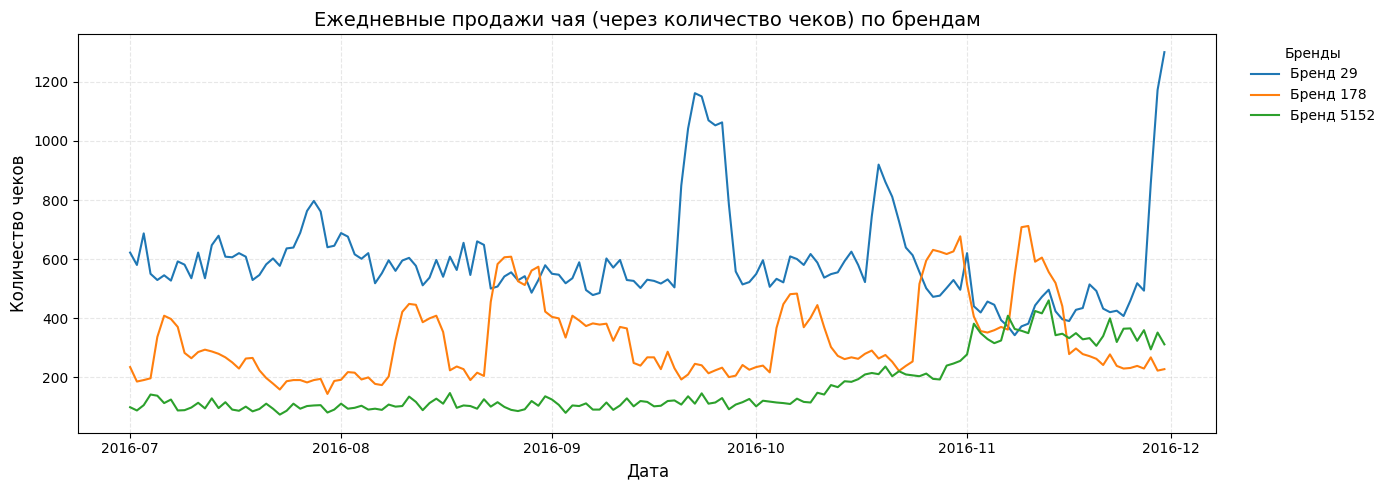

In [29]:
"""
Визуализация временных рядов ежедневных продаж (proxy через receipts_count) по брендам.
Цель: оценить общую динамику, выявить резкие скачки, разрывы и различия в масштабе между брендами.
"""

# ------------------------------------------------------------------
# 1. Построение линейного графика по всем брендам
# ------------------------------------------------------------------
plt.figure(figsize=(14, 5))

for brand_id, group in df.groupby("brand_id"):
    group = group.sort_values("date")
    plt.plot(
        group["date"],
        group["receipts_count"],
        label=f"Бренд {brand_id}"
    )

# ------------------------------------------------------------------
# 2. Оформление графика
# ------------------------------------------------------------------
plt.title("Ежедневные продажи чая (через количество чеков) по брендам", fontsize=14)
plt.xlabel("Дата", fontsize=12)
plt.ylabel("Количество чеков", fontsize=12)
plt.legend(
    title="Бренды",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)
plt.grid(alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()


In [30]:
"""
Выделение данных по бренду Ahmad Tea.
Цель: изолировать временной ряд Ahmad для дальнейшего анализа остатков и эффекта рекламы.
"""

# ------------------------------------------------------------------
# 1. Задание ID бренда Ahmad
# ------------------------------------------------------------------
AHMAD_ID = 178

# ------------------------------------------------------------------
# 2. Фильтрация и подготовка датасета по Ahmad
# ------------------------------------------------------------------
ahmad = (
    df[df["brand_id"] == AHMAD_ID]
    .sort_values("date")
    .copy()
)

# Проверка на наличие данных
assert not ahmad.empty, f"Не найдено наблюдений для brand_id = {AHMAD_ID}. Проверьте корректность ID и исходный датасет."

print(f"Для бренда Ahmad (ID {AHMAD_ID}) загружено {len(ahmad)} наблюдений.")
print("\nПервые 5 строк данных:")
print(ahmad.head())


Для бренда Ahmad (ID 178) загружено 153 наблюдений.

Первые 5 строк данных:
    brand_id       date  receipts_count
1        178 2016-07-01             234
4        178 2016-07-02             185
7        178 2016-07-03             190
10       178 2016-07-04             196
13       178 2016-07-05             336


## Парсинг данных

In [31]:
"""
Извлечение дат эфиров из веб‑страницы.
Цель: получить список дат трансляций, попадающих в период наблюдений по продажам, 
чтобы далее анализировать эффект рекламы вокруг этих дат.
"""

# ------------------------------------------------------------------
# 1. Запрос к странице с архивом эфиров
# ------------------------------------------------------------------
url = "https://xn----etbqgrg5bs.xn--p1ai/igry-2010-yh/sezon-2016"

response = requests.get(
    url,
    timeout=30,
    headers={"User-Agent": "Mozilla/5.0"}
)
response.raise_for_status()
response.encoding = response.apparent_encoding

# ------------------------------------------------------------------
# 2. Парсинг текста и извлечение дат в формате DD.MM.YYYY
# ------------------------------------------------------------------
soup = BeautifulSoup(response.text, "html.parser")
page_text = soup.get_text(" ", strip=True)

date_strings = re.findall(
    r"\b\d{2}\.\d{2}\.\d{4}\b",
    page_text
)

# Преобразуем строки в даты, убираем дубликаты и некорректные значения
episode_dates_raw = (
    pd.Series(date_strings)
    .drop_duplicates()
    .apply(lambda x: pd.to_datetime(x, format="%d.%m.%Y", errors="coerce"))
    .dropna()
    .sort_values()
)

episode_dates = pd.DatetimeIndex(episode_dates_raw).unique()

# ------------------------------------------------------------------
# 3. Фильтрация дат по периоду наблюдений в данных о продажах
# ------------------------------------------------------------------
min_date = df["date"].min()
max_date = df["date"].max()

episode_dates = episode_dates[
    (episode_dates >= min_date) &
    (episode_dates <= max_date)
]

# ------------------------------------------------------------------
# 4. Вывод результатов
# ------------------------------------------------------------------
print(f"Найдено {len(episode_dates)} дат эфиров в периоде наблюдений ({min_date.date()} – {max_date.date()})")
print("Даты эфиров:")
print(episode_dates)


Найдено 7 дат эфиров в периоде наблюдений (2016-07-01 – 2016-11-30)
Даты эфиров:
DatetimeIndex(['2016-09-25', '2016-10-02', '2016-10-09', '2016-10-16',
               '2016-10-23', '2016-11-20', '2016-11-27'],
              dtype='datetime64[ns]', freq=None)


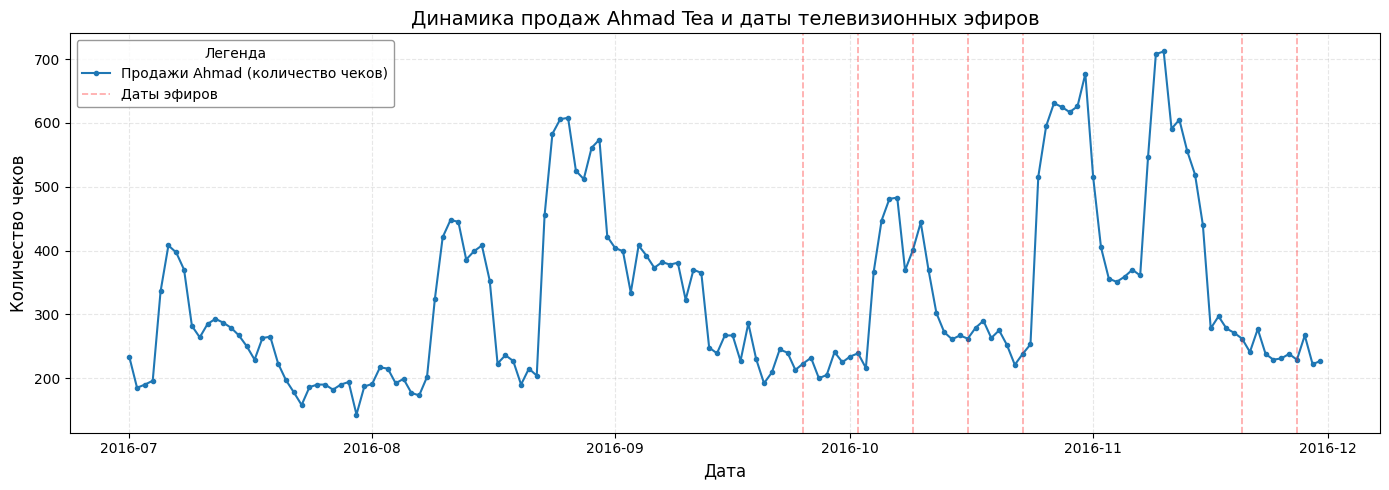

Всего отображено дат эфиров: 7
Диапазон дат эфиров: с 2016-09-25 по 2016-11-27


In [32]:
"""
Сопоставление динамики продаж Ahmad Tea с датами эфиров.
Цель: визуально оценить, наблюдаются ли всплески продаж в дни трансляций или в ближайшие к ним дни.
"""

# ------------------------------------------------------------------
# 1. Построение временного ряда продаж Ahmad
# ------------------------------------------------------------------
plt.figure(figsize=(14, 5))

plt.plot(
    ahmad["date"],
    ahmad["receipts_count"],
    marker=".",
    linestyle="-",
    color="#1f77b4",
    label="Продажи Ahmad (количество чеков)"
)

# ------------------------------------------------------------------
# 2. Добавление вертикальных линий по датам эфиров
# ------------------------------------------------------------------
for i, date in enumerate(episode_dates):
    plt.axvline(
        date,
        color="red",
        alpha=0.35,
        linestyle="--",
        linewidth=1.2,
        label="Даты эфиров" if i == 0 else None
    )

# ------------------------------------------------------------------
# 3. Оформление графика
# ------------------------------------------------------------------
plt.title("Динамика продаж Ahmad Tea и даты телевизионных эфиров", fontsize=14)
plt.xlabel("Дата", fontsize=12)
plt.ylabel("Количество чеков", fontsize=12)

# Легенда внутри фигуры (вместо вынесения вправо)
plt.legend(
    title="Легенда",
    loc="upper left",
    frameon=True,
    facecolor="white",
    edgecolor="gray"
)
plt.grid(alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 4. Вывод статистики по эфирам
# ------------------------------------------------------------------
print(f"Всего отображено дат эфиров: {len(episode_dates)}")
if len(episode_dates) > 0:
    print(f"Диапазон дат эфиров: с {episode_dates.min().date()} по {episode_dates.max().date()}")




## Логика построения базового прогноза продаж (медиана по аналогичным дням недели)

### Цель

Сформировать прогноз «базового» уровня продаж для каждого дня, чтобы в дальнейшем выделить эффект внешних воздействий (например, ТВ‑рекламы). Прогноз строится как медиана продаж за 4 предыдущие недели для того же дня недели. Такой подход позволяет учесть недельную сезонность и при этом быть устойчивым к выбросам.

### Исходные данные и подготовка ряда

- В качестве показателя продаж используется `receipts_count` (количество чеков) из датафрейма `ahmad`.
- Ряд приводится к ежедневной частоте (`asfreq("D")`), в результате чего пропущенные даты становятся значениями `NaN`.
- Наличие пропусков критично: автоматическое заполнение нулями исказит медиану, поэтому при обнаружении пропусков код прерывается с ошибкой — пропуски нужно исследовать и обработать отдельно.

---

### Пошаговая логика расчёта прогноза

1. **Формирование временного ряда.**  
   Данные сортируются по дате и приводятся к ежедневной частоте. Это позволяет явно увидеть разрывы в наблюдениях.

2. **Проверка на пропуски.**  
   Перед расчётом прогноза проверяется наличие `NaN`. Если пропуски есть, выполнение останавливается: требуется ручная проверка выгрузки данных.

3. **Скользящее окно в 28 дней (4 недели).**  
   Для каждой даты начиная с 28‑го дня строится окно из 28 предыдущих дней. Это минимальный горизонт, который гарантирует наличие до 4 наблюдений для аналогичного дня недели (например, 4 понедельников).

4. **Отбор дней с тем же днём недели.**  
   Из окна выбираются только те дни, у которых `dayofweek` совпадает с текущим днём. Таким образом, понедельник сравнивается только с понедельниками, вторник — с вторниками и т. д.

5. **Расчёт прогноза через медиану.**  
   Прогноз для текущего дня равен медиане отобранных 4 значений. Медиана предпочтительнее среднего, потому что устойчива к случайным всплескам и провалам продаж.

6. **Расчёт остатков и относительной ошибки.**  
   - Остаток: `residual = actual − predicted` — показывает отклонение факта от базового уровня.  
   - Относительная ошибка в процентах: `relative_error_pct = 100 × residual / predicted`.  
     При делении на ноль прогнозное значение заменяется на `NaN`, чтобы избежать некорректных вычислений.



In [33]:
"""
Прогноз продаж Ahmad Tea на основе сезонности по дням недели.
Цель: построить прогноз как медиану 4 предыдущих наблюдений с тем же днём недели,
чтобы отделить эффект рекламы от обычной недельной сезонности.
"""

# ------------------------------------------------------------------
# 1. Подготовка временного ряда
# ------------------------------------------------------------------
series = (
    ahmad.set_index("date")["receipts_count"]
    .sort_index()
    .asfreq("D")
)

missing_count = series.isna().sum()
print(f"Пропуски дневных наблюдений: {missing_count}")

if missing_count > 0:
    raise ValueError(
        f"Обнаружены пропущенные даты ({missing_count} шт.). "
        "Проверьте целостность данных и обработайте пропуски перед прогнозированием."
    )

# ------------------------------------------------------------------
# 2. Расчёт прогноза методом медианы по аналогичным дням недели
# ------------------------------------------------------------------
forecast = pd.Series(index=series.index, dtype=float)

for i in range(28, len(series)):
    # Берём окно из предыдущих 28 дней
    history = series.iloc[i - 28:i]

    # Фильтруем дни с тем же днём недели, что и текущая дата
    same_weekday = history[
        history.index.dayofweek == series.index[i].dayofweek
    ]

    # Прогноз — медиана значений за аналогичные дни недели
    if len(same_weekday) >= 4:
        forecast.iloc[i] = same_weekday.median()
    else:
        # Если недостаточно истории — оставляем NaN (не заполняем искусственно)
        forecast.iloc[i] = np.nan

# ------------------------------------------------------------------
# 3. Формирование таблицы результатов и расчёт метрик
# ------------------------------------------------------------------
results = pd.DataFrame({
    "actual": series,
    "predicted": forecast
})

# Остаток (факт − прогноз)
results["residual"] = results["actual"] - results["predicted"]

# Относительная ошибка в процентах (защита от деления на ноль)
results["relative_error_pct"] = (
    100 * results["residual"] / results["predicted"].replace(0, np.nan)
)

# ------------------------------------------------------------------
# 4. Вывод результатов
# ------------------------------------------------------------------
print("\nПервые строки результатов прогноза (без пропусков):")
print(results.dropna().head())

print(f"\nВсего рассчитано прогнозов: {results['predicted'].notna().sum()}")
print(f"Пропущено прогнозов из‑за недостатка истории: {results['predicted'].isna().sum()}")


Пропуски дневных наблюдений: 0

Первые строки результатов прогноза (без пропусков):
            actual  predicted  residual  relative_error_pct
date                                                       
2016-07-29     194      250.5     -56.5          -22.554890
2016-07-30     143      217.5     -74.5          -34.252874
2016-07-31     187      209.5     -22.5          -10.739857
2016-08-01     191      229.5     -38.5          -16.775599
2016-08-02     217      279.0     -62.0          -22.222222

Всего рассчитано прогнозов: 125
Пропущено прогнозов из‑за недостатка истории: 28


In [34]:
"""
Оценка качества прогноза продаж Ahmad Tea.
Цель: количественно оценить точность прогноза с помощью MAE и RMSE, 
чтобы понять, насколько модель отражает обычную сезонность до анализа эффекта рекламы.
"""

# ------------------------------------------------------------------
# 1. Подготовка данных для расчёта метрик
# ------------------------------------------------------------------
valid = results.dropna(subset=["predicted"])

if valid.empty:
    raise ValueError("Нет валидных прогнозов для расчёта метрик. Проверьте этап построения прогноза.")

# ------------------------------------------------------------------
# 2. Расчёт метрик качества прогноза
# ------------------------------------------------------------------
mae = mean_absolute_error(valid["actual"], valid["predicted"])
rmse = np.sqrt(mean_squared_error(valid["actual"], valid["predicted"]))

# ------------------------------------------------------------------
# 3. Вывод результатов оценки
# ------------------------------------------------------------------
print("Оценка качества прогноза:")
print(f"   Средняя абсолютная ошибка (MAE): {mae:.2f} ")
print(f"   Среднеквадратичная ошибка (RMSE): {rmse:.2f} ")

print(f"\nДля расчёта использовано {len(valid)} наблюдений с валидным прогнозом.")
if len(valid) < len(results):
    print(f" Часть наблюдений исключена из расчёта из‑за отсутствия прогноза.")


Оценка качества прогноза:
   Средняя абсолютная ошибка (MAE): 141.67 
   Среднеквадратичная ошибка (RMSE): 180.94 

Для расчёта использовано 125 наблюдений с валидным прогнозом.
 Часть наблюдений исключена из расчёта из‑за отсутствия прогноза.


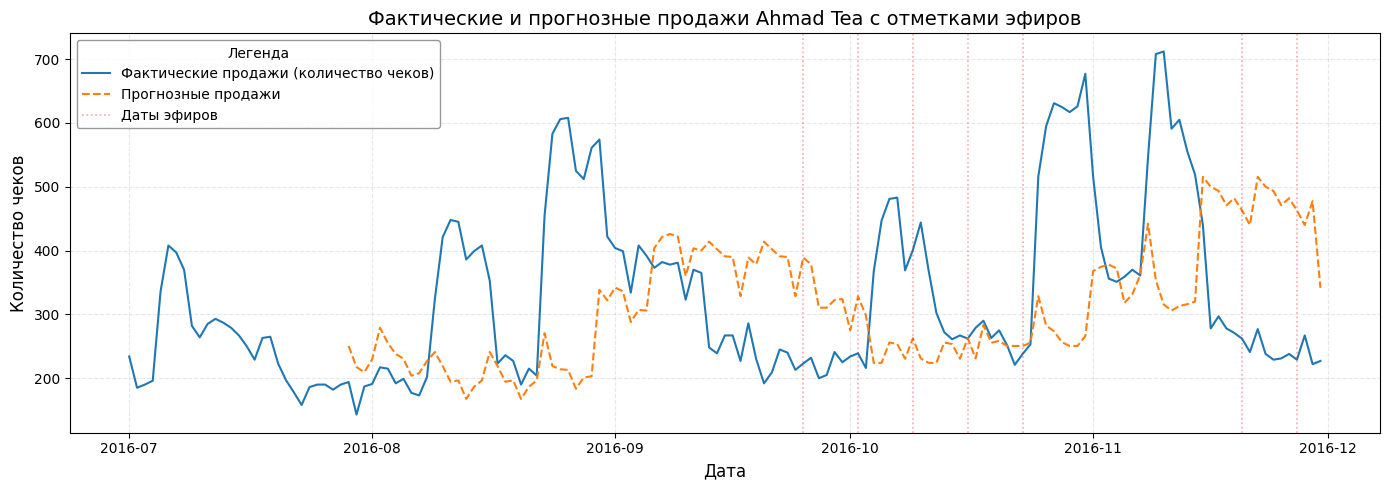

Для визуализации использовано 125 наблюдений с валидным прогнозом.
Часть дат не имеет прогноза из‑за недостатка истории (первые 28 дней и дни без 4 аналогов по дню недели).


In [35]:
"""
Сравнение фактических и прогнозных продаж Ahmad Tea.
Цель: визуально оценить качество прогноза и сопоставить отклонения с датами эфиров, 
чтобы предварительно выявить возможные всплески продаж, связанные с рекламой.
"""

# ------------------------------------------------------------------
# 1. Подготовка фигуры и построение основных линий
# ------------------------------------------------------------------
plt.figure(figsize=(14, 5))

plt.plot(
    results.index,
    results["actual"],
    color="#1f77b4",
    linewidth=1.5,
    label="Фактические продажи (количество чеков)"
)

plt.plot(
    results.index,
    results["predicted"],
    color="#ff7f0e",
    linestyle="--",
    linewidth=1.5,
    label="Прогнозные продажи"
)

# ------------------------------------------------------------------
# 2. Добавление вертикальных линий по датам эфиров
# ------------------------------------------------------------------
for i, date in enumerate(episode_dates):
    plt.axvline(
        date,
        color="red",
        alpha=0.35,
        linestyle=":",
        linewidth=1.2,
        label="Даты эфиров" if i == 0 else None
    )

# ------------------------------------------------------------------
# 3. Оформление графика
# ------------------------------------------------------------------
plt.title("Фактические и прогнозные продажи Ahmad Tea с отметками эфиров", fontsize=14)
plt.xlabel("Дата", fontsize=12)
plt.ylabel("Количество чеков", fontsize=12)

plt.legend(
    title="Легенда",
    loc="upper left",
    frameon=True,
    facecolor="white",
    edgecolor="gray"
)
plt.grid(alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 4. Вывод справочной статистики
# ------------------------------------------------------------------
valid_count = results.dropna(subset=["predicted"]).shape[0]
print(f"Для визуализации использовано {valid_count} наблюдений с валидным прогнозом.")
if results["predicted"].isna().sum() > 0:
    print(f"Часть дат не имеет прогноза из‑за недостатка истории (первые 28 дней и дни без 4 аналогов по дню недели).")


In [36]:
"""
Анализ ошибок прогноза в первые дни после эфиров.
Цель: проверить, наблюдаются ли систематические положительные отклонения (всплески продаж) 
в течение 3 дней после трансляций — это может служить индикатором эффекта рекламы.
"""

# ------------------------------------------------------------------
# 1. Формирование дат в окне «после эфира» (1–3 дня)
# ------------------------------------------------------------------
post_broadcast_dates = pd.DatetimeIndex([
    episode_date + pd.Timedelta(days=offset)
    for episode_date in episode_dates
    for offset in range(1, 4)
]).unique()

# ------------------------------------------------------------------
# 2. Выборка наблюдений в пост‑эфирном окне
# ------------------------------------------------------------------
post_results = results.loc[
    results.index.intersection(post_broadcast_dates)
].dropna(subset=["predicted"]).copy()

print(f"Найдено {len(post_results)} наблюдений в окне 1–3 дня после эфиров.")

if len(post_results) == 0:
    print("В пост‑эфирном окне нет валидных прогнозов. Проверьте пересечение дат и наличие истории для прогноза.")
else:
    # ------------------------------------------------------------------
    # 3. Вывод таблицы ошибок в пост‑эфирном окне
    # ------------------------------------------------------------------
    print("\nНаблюдения после эфиров (факт, прогноз, остаток):")
    print(post_results[["actual", "predicted", "residual"]])

    # ------------------------------------------------------------------
    # 4. Расчёт и вывод статистики по остаткам
    # ------------------------------------------------------------------
    positive_residual_count = (post_results["residual"] > 0).sum()
    mean_residual = round(post_results["residual"].mean(), 2)
    median_residual = round(post_results["residual"].median(), 2)
    mean_residual_all = round(results["residual"].dropna().mean(), 2)

    print(f"\nКоличество дней с положительным остатком (факт > прогноз): {positive_residual_count}")
    print(f"   Средний остаток в пост‑эфирном окне: {mean_residual}")
    print(f"   Медианный остаток в пост‑эфирном окне: {median_residual}")
    print(f"   Средний остаток по всем прогнозным дням: {mean_residual_all}")

    if mean_residual > 0 and mean_residual > mean_residual_all:
        print("Наблюдается смещение остатков вверх в пост‑эфирном окне относительно общего среднего — потенциальный признак эффекта рекламы.")
    else:
        print("ℹСмещение остатков в пост‑эфирном окне не выражено или незначительно относительно общего фона.")


Найдено 21 наблюдений в окне 1–3 дня после эфиров.

Наблюдения после эфиров (факт, прогноз, остаток):
            actual  predicted  residual
2016-09-26     232      378.5    -146.5
2016-09-27     200      310.5    -110.5
2016-09-28     205      310.5    -105.5
2016-10-03     216      298.5     -82.5
2016-10-04     367      224.0     143.0
2016-10-05     447      224.0     223.0
2016-10-10     444      231.0     213.0
2016-10-11     369      224.0     145.0
2016-10-12     302      224.0      78.0
2016-10-17     279      231.0      48.0
2016-10-18     290      283.5       6.5
2016-10-19     263      255.5       7.5
2016-10-24     253      255.5      -2.5
2016-10-25     516      328.5     187.5
2016-10-26     595      282.5     312.5
2016-11-21     241      440.0    -199.0
2016-11-22     277      515.5    -238.5
2016-11-23     238      500.0    -262.0
2016-11-28     267      440.0    -173.0
2016-11-29     222      477.5    -255.5
2016-11-30     227      341.5    -114.5

Количество дней с

In [37]:
"""
Подготовка остатков прогноза для статистического теста.
Цель: разделить остатки на две группы — «после эфира» и «обычные дни» — 
чтобы далее проверить статистическую значимость различий между ними.
"""

# ------------------------------------------------------------------
# 1. Подготовка датафрейма с валидными прогнозами
# ------------------------------------------------------------------
test_df = results.dropna(subset=["predicted"]).copy()

if test_df.empty:
    raise ValueError("Нет валидных прогнозов для проведения статистического анализа. Проверьте предыдущие этапы.")

# ------------------------------------------------------------------
# 2. Маркировка дней как «после эфира» или «обычные»
# ------------------------------------------------------------------
test_df["post_broadcast"] = test_df.index.isin(post_broadcast_dates)

post_residuals = test_df.loc[
    test_df["post_broadcast"], "residual"
]

ordinary_residuals = test_df.loc[
    ~test_df["post_broadcast"], "residual"
]

# ------------------------------------------------------------------
# 3. Вывод базовой статистики по группам
# ------------------------------------------------------------------
count_post = len(post_residuals)
count_ordinary = len(ordinary_residuals)

mean_post = round(post_residuals.mean(), 2)
mean_ordinary = round(ordinary_residuals.mean(), 2)
diff_means = round(mean_post - mean_ordinary, 2)

print(f"Объём выборок для теста:")
print(f"   Дни после эфиров: {count_post} наблюдений")
print(f"   Обычные дни: {count_ordinary} наблюдений")

print(f"\nСредние остатки:")
print(f"   После эфиров: {mean_post}")
print(f"   В обычные дни: {mean_ordinary}")
print(f"   Разница средних: {diff_means}")

# ------------------------------------------------------------------
# 4. Интерпретация разницы средних
# ------------------------------------------------------------------
if diff_means > 0:
    print(f"Средний остаток в дни после эфиров выше на {diff_means} чека — это может указывать на положительный эффект рекламы.")
else:
    print(f"Средний остаток после эфиров не превышает общий фон (разница: {diff_means}). Эффект не выражен или направлен в другую сторону.")

# Сохраняем серии для следующего шага (статистический тест)
# post_residuals, ordinary_residuals будут использованы в следующей ячейке


Объём выборок для теста:
   Дни после эфиров: 21 наблюдений
   Обычные дни: 104 наблюдений

Средние остатки:
   После эфиров: -15.52
   В обычные дни: 42.39
   Разница средних: -57.91
Средний остаток после эфиров не превышает общий фон (разница: -57.91). Эффект не выражен или направлен в другую сторону.


In [38]:
"""
Односторонний t‑тест Уэлча для проверки эффекта рекламы.
Цель: статистически проверить гипотезу о том, что в дни после эфиров остатки прогноза 
(факт − прогноз) систематически выше, чем в обычные дни — то есть продажи выше ожидаемых.

Нулевая гипотеза (H₀): среднее остатков в пост‑эфирные дни ≤ среднему в обычные дни.
Альтернативная гипотеза (H₁): среднее остатков в пост‑эфирные дни > среднему в обычные дни.
"""

# ------------------------------------------------------------------
# 1. Проверка достаточности данных для теста
# ------------------------------------------------------------------
if len(post_residuals) < 3:
    raise ValueError(
        f"Слишком мало наблюдений в группе «после эфира» ({len(post_residuals)} шт.) "
        "для надёжного проведения t‑теста. Рассмотрите расширение окна или накопление данных."
    )
if len(ordinary_residuals) < 5:
    raise ValueError(
        f"Слишком мало наблюдений в контрольной группе ({len(ordinary_residuals)} шт.). "
        "Для корректного теста желательно иметь больше обычных дней."
    )

# ------------------------------------------------------------------
# 2. Проведение одностороннего t‑теста Уэлча
# ------------------------------------------------------------------
test_result = stats.ttest_ind(
    post_residuals,
    ordinary_residuals,
    equal_var=False,          # t‑тест Уэлча (не предполагаем равенство дисперсий)
    alternative="greater"     # односторонний тест: проверяем, что пост‑эфирные остатки больше
)

t_stat = round(test_result.statistic, 4)
p_val = round(test_result.pvalue, 4)

# ------------------------------------------------------------------
# 3. Вывод результатов теста
# ------------------------------------------------------------------
print("Результаты одностороннего t‑теста Уэлча:")
print(f"   t‑статистика: {t_stat}")
print(f"   p‑значение: {p_val}")

# ------------------------------------------------------------------
# 4. Интерпретация с учётом уровня значимости α = 0.05
# ------------------------------------------------------------------
alpha = 0.05
if p_val < alpha:
    print(f"\nНа уровне значимости {alpha} результат статистически значим: "
          f"есть основания считать, что после эфиров продажи превышают прогноз сильнее, чем в обычные дни.")
else:
    print(f"\nНа уровне значимости {alpha} нет достаточных оснований отвергнуть нулевую гипотезу — "
          "систематический рост продаж после эфиров не подтверждён статистически.")

print(f"   Для справки: размеры выборок — пост‑эфирные дни: {len(post_residuals)}, обычные дни: {len(ordinary_residuals)}")


Результаты одностороннего t‑теста Уэлча:
   t‑статистика: -1.3917
   p‑значение: 0.9128

На уровне значимости 0.05 нет достаточных оснований отвергнуть нулевую гипотезу — систематический рост продаж после эфиров не подтверждён статистически.
   Для справки: размеры выборок — пост‑эфирные дни: 21, обычные дни: 104


## Интерпретация результатов одностороннего t‑теста Уэлча

### Полученные значения
- **t‑статистика:** −1.3917  
- **p‑значение:** 0.9128  

### Вывод по тесту
Результат **не позволяет отвергнуть нулевую гипотезу**. Нет статистически значимого подтверждения того, что остатки (отклонения от прогноза) в постэфирном периоде выше, чем в обычные дни.

Отрицательное значение t‑статистики говорит о том, что в среднем остатки после эфира были **ниже**, чем в контрольной группе.

### Важные оговорки
- Это **не доказывает отсутствие эффекта рекламы**: возможна ситуация, когда фактические продажи росли, но прогноз (медиана по прошлым неделям) оказался завышен — тогда остатки будут отрицательными.
- Эффект мог проявиться с **лагом** (на 2–4‑й день после эфира), а текущее окно его «размывает».
- Из‑за **малого объёма выборки** тест имеет низкую мощность — даже реальный эффект может не дать значимого p‑значения.




## Построим профиль отклонений продаж вокруг ТВ‑эфиров

### Общая идея

Цель — выявить, меняется ли отклонение фактических продаж от прогнозного уровня («остаток») в окрестности даты эфира. Для этого мы:
1. Формируем единое окно анализа вокруг каждого эфира: от −5 до +5 дней.
2. Собираем остатки для всех доступных дат в этих окнах.
3. Агрегируем данные по «дню относительно эфира» (event_day = −5…5).
4. Визуализируем динамику среднего и медианного остатка, чтобы увидеть возможную реакцию на рекламу.

Индекс results приведён к формату даты (без времени). Уникальных дат эфиров: 7
Собрано 75 наблюдений остатков вокруг эфиров.

Сводная статистика остатков по дням относительно эфира:


,count,mean,median,std
event_day,,,,
-5,7,-50.285714,-75.50,156.999166
-4,7,-67.714286,-105.50,177.988730
-3,7,-61.571429,-81.50,163.883452
-2,7,-63.357143,-99.00,159.049184
-1,7,-66.571429,-41.00,135.055985
0,7,-80.642857,-89.00,131.940553
1,7,-48.928571,-82.50,146.469402
2,7,-17.500000,6.50,186.592917
3,7,19.857143,7.50,201.515035


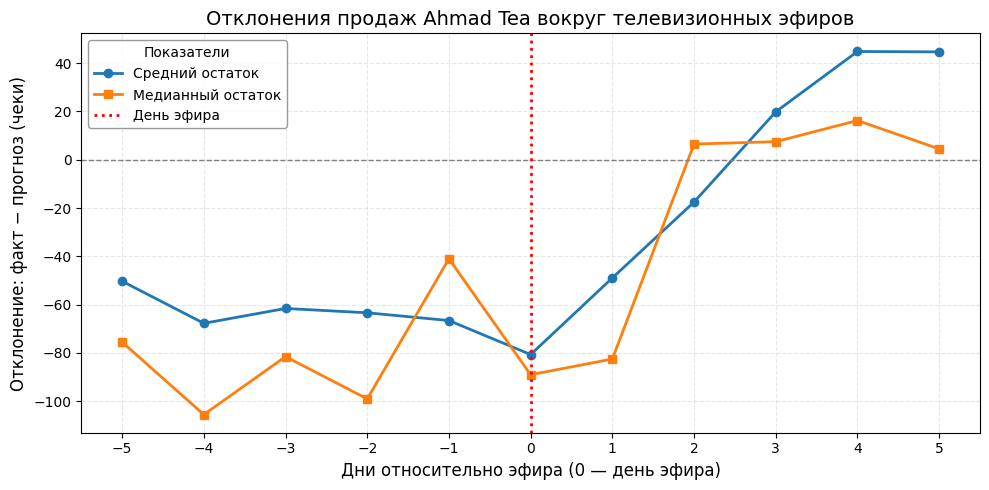

Ключевые наблюдения по профилю:
   Максимальный средний остаток приходится на день: 4 (относительно эфира)
   Максимальный медианный остаток приходится на день: 4
   Пик отклонений смещён в сторону дней после эфира — это согласуется с гипотезой об отложенном эффекте рекламы.


In [39]:
"""
Построение профиля отклонений продаж вокруг эфиров.
Цель: оценить динамику остатков (факт − прогноз) в окне ±5 дней относительно даты эфира — 
это позволяет увидеть, когда именно проявляется потенциальный эффект рекламы: до, в день или после эфира.
"""

# ------------------------------------------------------------------
# 1. Приведение индексов и дат к единому формату (без времени)
# ------------------------------------------------------------------
results.index = pd.to_datetime(results.index).normalize()
episode_dates = pd.DatetimeIndex(
    pd.to_datetime(episode_dates)
).normalize().unique()

print(f"Индекс results приведён к формату даты (без времени). Уникальных дат эфиров: {len(episode_dates)}")

# ------------------------------------------------------------------
# 2. Сбор остатков в окне ±5 дней вокруг каждого эфира
# ------------------------------------------------------------------
event_rows = []

for episode_date in episode_dates:
    for offset in range(-5, 6):
        observation_date = episode_date + pd.Timedelta(days=offset)

        if observation_date in results.index:
            residual = results.loc[observation_date, "residual"]

            # Пропускаем даты, для которых прогноз не был рассчитан (NaN)
            if pd.notna(residual):
                event_rows.append({
                    "episode_date": episode_date,
                    "event_day": offset,
                    "date": observation_date,
                    "residual": residual
                })

event_df = pd.DataFrame(event_rows)

if event_df.empty:
    raise ValueError("Не удалось собрать ни одного валидного остатка в окне ±5 дней. Проверьте наличие прогнозов и пересечение дат.")

print(f"Собрано {len(event_df)} наблюдений остатков вокруг эфиров.")

# ------------------------------------------------------------------
# 3. Агрегация статистики по дням относительно эфира
# ------------------------------------------------------------------
event_summary = (
    event_df.groupby("event_day")["residual"]
    .agg(["count", "mean", "median", "std"])
    .reindex(range(-5, 6))
)

print("\nСводная статистика остатков по дням относительно эфира:")
display(event_summary)

# ------------------------------------------------------------------
# 4. Построение графика профиля отклонений
# ------------------------------------------------------------------
plt.figure(figsize=(10, 5))

plt.plot(
    event_summary.index,
    event_summary["mean"],
    marker="o",
    linewidth=2,
    color="#1f77b4",
    label="Средний остаток"
)
plt.plot(
    event_summary.index,
    event_summary["median"],
    marker="s",
    linewidth=2,
    color="#ff7f0e",
    label="Медианный остаток"
)

plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.axvline(0, color="red", linestyle=":", linewidth=2, label="День эфира")

plt.xticks(range(-5, 6))
plt.xlabel("Дни относительно эфира (0 — день эфира)", fontsize=12)
plt.ylabel("Отклонение: факт − прогноз (чеки)", fontsize=12)
plt.title("Отклонения продаж Ahmad Tea вокруг телевизионных эфиров", fontsize=14)

plt.legend(
    title="Показатели",
    loc="upper left",
    frameon=True,
    facecolor="white",
    edgecolor="gray"
)
plt.grid(alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 5. Краткая интерпретация профиля
# ------------------------------------------------------------------
max_mean_day = event_summary["mean"].idxmax()
max_median_day = event_summary["median"].idxmax()

print("Ключевые наблюдения по профилю:")
print(f"   Максимальный средний остаток приходится на день: {max_mean_day} (относительно эфира)")
print(f"   Максимальный медианный остаток приходится на день: {max_median_day}")

if max_mean_day > 0:
    print("   Пик отклонений смещён в сторону дней после эфира — это согласуется с гипотезой об отложенном эффекте рекламы.")
elif max_mean_day == 0:
    print("   Наибольшее отклонение наблюдается в день эфира — эффект может быть мгновенным.")
else:
    print("   Пик отклонений приходится на дни до эфира — возможны иные факторы (например, промо‑активности).")



## Анализ эффекта ТВ‑рекламы: расчёт средних остатков по периодам и проверка гипотез

### Цель этапа

Оценить, меняется ли отклонение фактических продаж от прогноза (остаток) в разные периоды вокруг эфира:
- **до эфира** («before») — базовый уровень;
- **сразу после** («early_after») — возможная первая волна эффекта;
- **позднее после** («late_after») — затухание или усиление эффекта.

Для этого агрегируем остатки по периодам для каждого отдельного эфира, а затем проверяем две гипотезы с помощью непараметрического критерия Уилкоксона (он подходит при малом числе эфиров и возможных выбросах).


In [40]:
"""
Анализ эффекта рекламы по периодам вокруг каждого эфира.
Цель: для каждого выпуска рассчитать средние остатки в трёх периодах 
(до эфира, ранние дни после, поздние дни после) и проверить статистически:
1) растут ли остатки после эфира относительно периода до;
2) снижается ли эффект к поздним дням после эфира (затухание).
"""

# ------------------------------------------------------------------
# 1. Вспомогательная функция: среднее по строго заданному набору дней
# ------------------------------------------------------------------
def period_mean(group, days):
    """
    Возвращает среднее остатков только если для всех дней из списка days
    есть валидные наблюдения. Иначе — NaN. Это защищает от смещений, 
    когда для какого-то выпуска не хватает одного дня в периоде.
    """
    values = group.loc[group["event_day"].isin(days), "residual"]

    if len(values) != len(days):
        return np.nan

    return values.mean()

# ------------------------------------------------------------------
# 2. Расчёт средних по периодам для каждого выпуска
# ------------------------------------------------------------------
episode_results = []

for episode_date, group in event_df.groupby("episode_date"):
    episode_results.append({
        "episode_date": episode_date,
        "before": period_mean(group, [-5, -4, -3, -2, -1]),
        "early_after": period_mean(group, [1, 2]),
        "late_after": period_mean(group, [3, 4, 5])
    })

episode_results = pd.DataFrame(episode_results)

print(f"Рассчитано показателей по {len(episode_results)} выпускам.")

# Оставляем только выпуски, у которых есть полные данные по всем трём периодам
complete = episode_results.dropna(
    subset=["before", "early_after", "late_after"]
).copy()

if complete.empty:
    raise ValueError(
        "Нет ни одного выпуска с полными данными по всем трём периодам (±5 дней). "
        "Проверьте пересечения дат и наличие прогнозов."
    )

print(f"Для анализа использовано {len(complete)} выпусков с полными периодами.")

display(complete)

# ------------------------------------------------------------------
# 3. Тест 1: рост эффекта после эфира (ранние дни после vs до эфира)
# ------------------------------------------------------------------
if len(complete) >= 2:
    increase_test = stats.wilcoxon(
        complete["early_after"],
        complete["before"],
        alternative="greater"
    )

    median_before = round(complete["before"].median(), 2)
    median_early_after = round(complete["early_after"].median(), 2)

    print("\nТест 1: эффект после эфира выше, чем до эфира?")
    print(f"   Медиана (до эфира): {median_before}")
    print(f"   Медиана (ранние после): {median_early_after}")
    print(f"   p‑значение: {increase_test.pvalue:.4f}")

    alpha = 0.05
    if increase_test.pvalue < alpha:
        print(f"На уровне значимости {alpha} есть основания считать, что эффект рекламы проявляется после эфира.")
    else:
        print(f"На уровне значимости {alpha} статистически значимого роста после эфира не обнаружено.")
else:
    print("Недостаточно выпусков для проведения теста 1 (нужно ≥2).")

# ------------------------------------------------------------------
# 4. Тест 2: затухание эффекта к поздним дням (поздние после vs ранние после)
# ------------------------------------------------------------------
if len(complete) >= 2:
    fade_test = stats.wilcoxon(
        complete["late_after"],
        complete["early_after"],
        alternative="less"
    )

    median_late_after = round(complete["late_after"].median(), 2)

    print("\nТест 2: эффект затухает к поздним дням?")
    print(f"   Медиана (поздние после): {median_late_after}")
    print(f"   p‑значение: {fade_test.pvalue:.4f}")


    if fade_test.pvalue < alpha:
        print(f"На уровне значимости {alpha} есть основания считать, что эффект рекламы затухает к 3–5 дню.")
    else:
        print(f"На уровне значимости {alpha} статистически значимого затухания не обнаружено.")
else:
    print("Недостаточно выпусков для проведения теста 2 (нужно ≥2).")


Рассчитано показателей по 7 выпускам.
Для анализа использовано 6 выпусков с полными периодами.


,episode_date,before,early_after,late_after
0,2016-09-25,-165.3,-128.50,-95.333333
1,2016-10-02,-87.5,30.25,225.833333
2,2016-10-09,191.8,179.00,33.833333
3,2016-10-16,56.6,27.25,8.500000
4,2016-10-23,0.5,92.50,346.166667
5,2016-11-20,-179.6,-218.75,-255.500000



Тест 1: эффект после эфира выше, чем до эфира?
   Медиана (до эфира): -43.5
   Медиана (ранние после): 28.75
   p‑значение: 0.2812
На уровне значимости 0.05 статистически значимого роста после эфира не обнаружено.

Тест 2: эффект затухает к поздним дням?
   Медиана (поздние после): 21.17
   p‑значение: 0.7188
На уровне значимости 0.05 статистически значимого затухания не обнаружено.


### Что видно из результатов:
Поведение неоднородно: у некоторых эфиров (2016‑10‑02, 2016‑10‑23) есть выраженный рост остатков после эфира, у других (2016‑11‑20) — падение, у третьих (2016‑10‑16) — постепенное снижение.

Это говорит о том, что эффект может зависеть от внешних факторов (сезонность, акции, конкуренция) или от характеристик самого эфира/слота.

### Статистические тесты (критерий Уилкоксона для парных выборок)
Как ведут себя остатки после эфира по сравнению с периодом до?
Результаты:
Медиана before: −43.5
Медиана early_after: 28.75
p‑значение: 0.28125

### Вывод:
Cтатистически значимого подтверждения роста не наблюдается.

Хотя медианные значения говорят о росте (−43.5 → 28.75), при n=6 разброс и неоднородность между эфирами не позволяют сделать уверенный вывод.


## Сравнение динамики остатков Ahmad Tea с динамикой других брендов: поиск внешнего эффекта

### Контекст и цель анализа

Поскольку анализ остатков (факт − прогноз) только по Ahmad Tea не выявил статистически значимого эффекта рекламы, возникает гипотеза: возможно, на продажи влияют **общие рыночные факторы** (сезонность, промо у конкурентов, макрособытия), которые «размывают» эффект в остатках одного бренда.

### Цель: отделить специфический эффект рекламы Ahmad от общих рыночных факторов.
Подход:
- Строим прогноз и считаем остатки (факт − прогноз) для Ahmad и двух бенчмарк‑брендов.
- В качестве «рыночного фона» используем разницу продаж двух брендов (A−B).
  Если общий фактор одинаково влияет на оба бренда, он сократится в их разнице.
- Таким образом разница продаж двух брендов (A−B) и будет являться бенчмарком.
- Сравниваем динамику остатков Ahmad с динамикой бенчмарка вокруг дат эфиров:
    * корреляции,
    * профили по дням относительно эфира,
    * парные t‑тесты по эпизодам.

Входные объекты (должны быть определены до запуска):
- df: исходные данные (brand_id, date, receipts_count)
- results: датафрейм с остатками Ahmad (колонки actual, predicted, residual)
- episode_dates: список дат эфиров


In [41]:
# ------------------------------------------------------------------
# 1. Настройка ID брендов и функция прогноза
# ------------------------------------------------------------------
AHMAD_ID = 178
BRAND_A_ID = 29
BRAND_B_ID = 5152
brands_ids = [AHMAD_ID, BRAND_A_ID, BRAND_B_ID]

def forecast_by_weekday_median(series, window_days=28):
    """
    Прогноз как медиана 4 последних наблюдений с тем же днём недели.
    Это сглаживает выбросы и сохраняет недельную сезонность.
    """
    forecast = pd.Series(index=series.index, dtype=float)
    for i in range(window_days, len(series)):
        history = series.iloc[i - window_days:i]
        same_weekday = history[history.index.dayofweek == series.index[i].dayofweek]
        if len(same_weekday) >= 4:
            forecast.iloc[i] = same_weekday.tail(4).median()
        else:
            forecast.iloc[i] = np.nan
    return forecast

# ------------------------------------------------------------------
# 2. Расчёт остатков и построение бенчмарка
# ------------------------------------------------------------------
residuals_dict = {}
sales_dict = {}
available_brands = []

for bid in brands_ids:
    brand_df = df[df["brand_id"] == bid].sort_values("date").copy()
    if brand_df.empty:
        print(f"⚠️ Нет наблюдений для brand_id {bid}. Пропускаем.")
        continue

    series = (
        brand_df.set_index("date")["receipts_count"]
        .sort_index()
        .asfreq("D")
    )

    # Фильтр: достаточно данных для устойчивого прогноза
    if series.notna().sum() < 35:
        print(f"⚠️ Для brand_id {bid} слишком мало непустых наблюдений ({series.notna().sum()}) "
              "для устойчивого прогноза. Пропускаем.")
        continue

    pred = forecast_by_weekday_median(series)
    res = series - pred

    res_col_name = f"residual_brand_{bid}"
    sales_col_name = f"sales_brand_{bid}"

    residuals_dict[bid] = res.rename(res_col_name)
    sales_dict[bid] = series.rename(sales_col_name)
    available_brands.append(bid)

if len(available_brands) < 3:
    raise ValueError("Недостаточно брендов с полными данными для бенчмарка (нужно 3).")

res_df = pd.DataFrame({bid: residuals_dict[bid] for bid in available_brands})
sales_df = pd.DataFrame({bid: sales_dict[bid] for bid in available_brands})

res_df.columns = [f"residual_brand_{c}" for c in res_df.columns]
sales_df.columns = [f"sales_brand_{c}" for c in sales_df.columns]

col_a = f"sales_brand_{BRAND_A_ID}"
col_b = f"sales_brand_{BRAND_B_ID}"
benchmark = (sales_df[col_a] - sales_df[col_b]).rename("benchmark_diff_29_5152")

analysis_df = res_df.join(benchmark, how="left")
col_ahmad = f"sales_brand_{AHMAD_ID}"
if col_ahmad in sales_df.columns:
    analysis_df["actual_ahmad"] = sales_df[col_ahmad]

print("Датафрейм analysis_df построен. Колонки:", list(analysis_df.columns))


Датафрейм analysis_df построен. Колонки: ['residual_brand_178', 'residual_brand_29', 'residual_brand_5152', 'benchmark_diff_29_5152', 'actual_ahmad']


In [42]:
# ------------------------------------------------------------------
# 3. Выравнивание индексов и сбор данных вокруг эфиров
# ------------------------------------------------------------------
results_norm = results.copy()
results_norm.index = pd.to_datetime(results_norm.index).normalize()

episode_dates_norm = pd.DatetimeIndex(pd.to_datetime(episode_dates)).normalize().unique()

analysis_norm = analysis_df.copy()
analysis_norm.index = pd.to_datetime(analysis_norm.index).normalize()

event_rows = []
for episode_date in episode_dates_norm:
    for offset in range(-5, 6):
        observation_date = episode_date + pd.Timedelta(days=offset)
        if observation_date not in results_norm.index or observation_date not in analysis_norm.index:
            continue
        residual = results_norm.loc[observation_date, "residual"]
        benchmark = analysis_norm.loc[observation_date, "benchmark_diff_29_5152"]
        if pd.notna(residual) and pd.notna(benchmark):
            event_rows.append({
                "episode_date": episode_date,
                "event_day": offset,
                "date": observation_date,
                "residual": residual,
                "benchmark": benchmark,
                "actual_ahmad": analysis_norm.loc[observation_date, "actual_ahmad"],
            })

event_df = pd.DataFrame(event_rows)
if event_df.empty:
    raise ValueError("Нет совпадающих дат между residuals и бенчмарком. Проверьте диапазоны.")

event_summary = (
    event_df.groupby("event_day")
    .agg(
        count=("residual", "count"),
        mean_residual=("residual", "mean"),
        median_residual=("residual", "median"),
        mean_benchmark=("benchmark", "mean"),
        median_benchmark=("benchmark", "median"),
        mean_ahmad=("actual_ahmad", "mean"),
        median_ahmad=("actual_ahmad", "median"),
    )
    .reindex(range(-5, 6))
)

print("\nСводка по дням вокруг эфира:")
display(event_summary)




Сводка по дням вокруг эфира:


,count,mean_residual,median_residual,mean_benchmark,median_benchmark,mean_ahmad,median_ahmad
event_day,,,,,,,
-5,7,-50.285714,-75.50,407.285714,419.0,305.000000,290.0
-4,7,-67.714286,-105.50,431.000000,409.0,277.428571,263.0
-3,7,-61.571429,-81.50,441.000000,399.0,291.428571,272.0
-2,7,-63.357143,-99.00,441.428571,407.0,281.428571,252.0
-1,7,-66.571429,-41.00,456.857143,448.0,259.000000,238.0
0,7,-80.642857,-89.00,436.428571,430.0,264.857143,239.0
1,7,-48.928571,-82.50,448.428571,407.0,276.000000,253.0
2,7,-17.500000,6.50,462.142857,419.0,320.142857,290.0
3,7,19.857143,7.50,475.857143,409.0,325.285714,263.0


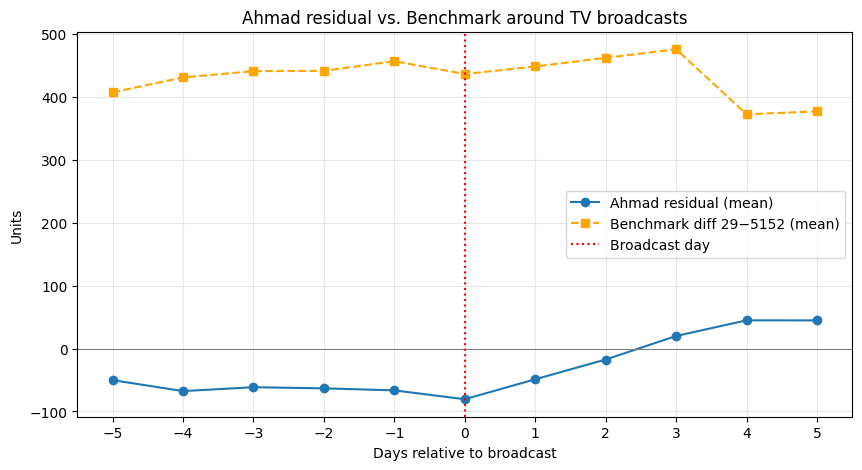

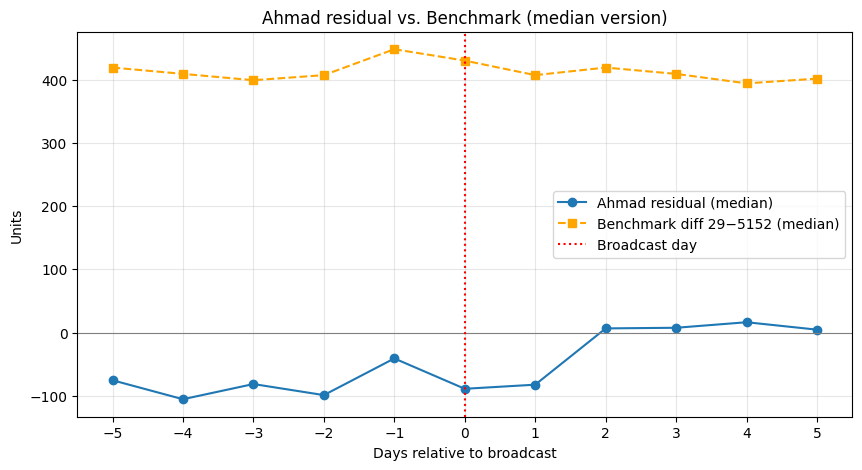

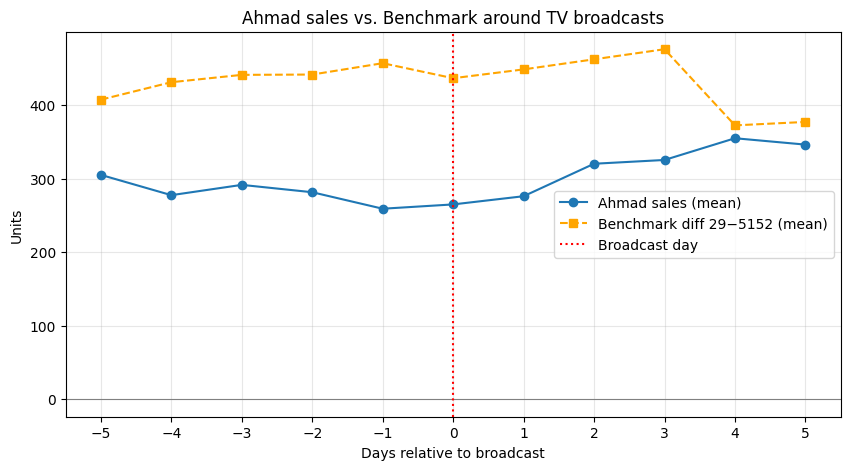

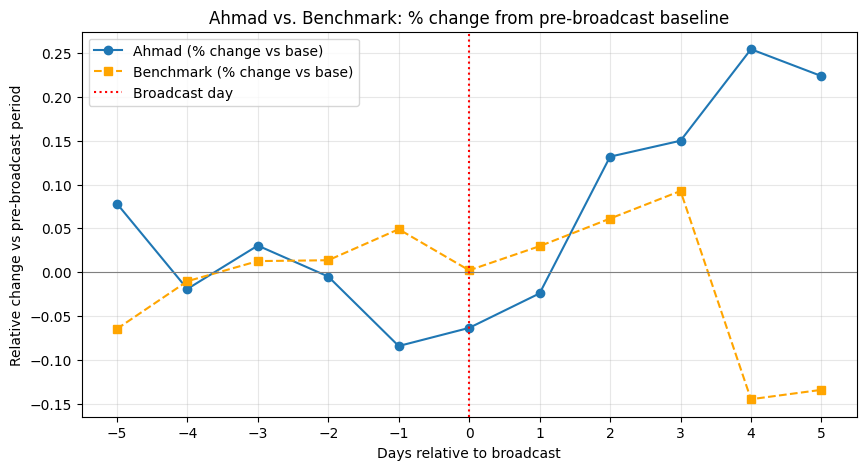

In [43]:
# ------------------------------------------------------------------
# 4. Визуализации
# ------------------------------------------------------------------
SHOW_PLOTS = True  # поставьте False, если нужны только числа

if SHOW_PLOTS:
    # Residual vs Benchmark (mean)
    plt.figure(figsize=(10, 5))
    plt.plot(event_summary.index, event_summary["mean_residual"], marker="o", label="Ahmad residual (mean)")
    plt.plot(event_summary.index, event_summary["mean_benchmark"], marker="s", linestyle="--", color="orange", label="Benchmark diff 29−5152 (mean)")
    plt.axhline(0, color="gray", linestyle="-", linewidth=0.8)
    plt.axvline(0, color="red", linestyle=":", label="Broadcast day")
    plt.xticks(range(-5, 6))
    plt.xlabel("Days relative to broadcast")
    plt.ylabel("Units")
    plt.title("Ahmad residual vs. Benchmark around TV broadcasts")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    # Residual vs Benchmark (median)
    plt.figure(figsize=(10, 5))
    plt.plot(event_summary.index, event_summary["median_residual"], marker="o", label="Ahmad residual (median)")
    plt.plot(event_summary.index, event_summary["median_benchmark"], marker="s", linestyle="--", color="orange", label="Benchmark diff 29−5152 (median)")
    plt.axhline(0, color="gray", linestyle="-", linewidth=0.8)
    plt.axvline(0, color="red", linestyle=":", label="Broadcast day")
    plt.xticks(range(-5, 6))
    plt.xlabel("Days relative to broadcast")
    plt.ylabel("Units")
    plt.title("Ahmad residual vs. Benchmark (median version)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    # Actual Ahmad vs Benchmark (mean)
    plt.figure(figsize=(10, 5))
    plt.plot(event_summary.index, event_summary["mean_ahmad"], marker="o", label="Ahmad sales (mean)")
    plt.plot(event_summary.index, event_summary["mean_benchmark"], marker="s", linestyle="--", color="orange", label="Benchmark diff 29−5152 (mean)")
    plt.axhline(0, color="gray", linestyle="-", linewidth=0.8)
    plt.axvline(0, color="red", linestyle=":", label="Broadcast day")
    plt.xticks(range(-5, 6))
    plt.xlabel("Days relative to broadcast")
    plt.ylabel("Units")
    plt.title("Ahmad sales vs. Benchmark around TV broadcasts")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    # Относительное изменение (relative change vs pre-broadcast)
    base_mask = (event_summary.index >= -5) & (event_summary.index <= -1)
    base_ahmad = event_summary.loc[base_mask, "mean_ahmad"].mean()
    base_bench = event_summary.loc[base_mask, "mean_benchmark"].mean()

    event_summary["rel_ahmad"] = (event_summary["mean_ahmad"] / base_ahmad) - 1
    event_summary["rel_bench"] = (event_summary["mean_benchmark"] / base_bench) - 1

    plt.figure(figsize=(10, 5))
    plt.plot(event_summary.index, event_summary["rel_ahmad"], marker="o", label="Ahmad (% change vs base)")
    plt.plot(event_summary.index, event_summary["rel_bench"], marker="s", linestyle="--", color="orange", label="Benchmark (% change vs base)")
    plt.axhline(0, color="gray", linestyle="-", linewidth=0.8)
    plt.axvline(0, color="red", linestyle=":", label="Broadcast day")
    plt.xticks(range(-5, 6))
    plt.xlabel("Days relative to broadcast")
    plt.ylabel("Relative change vs pre-broadcast period")
    plt.title("Ahmad vs. Benchmark: % change from pre-broadcast baseline")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()



In [44]:
# ------------------------------------------------------------------
# 5. Корреляции
# ------------------------------------------------------------------
valid = event_df.dropna(subset=["residual", "benchmark"])
if len(valid) > 10:
    corr_val_res_bench = valid["residual"].corr(valid["benchmark"], method="pearson")
    p_val_res_bench = stats.pearsonr(valid["residual"], valid["benchmark"]).pvalue
    print(f"\nКорреляция Пирсона (residual Ahmad vs benchmark): {corr_val_res_bench:.3f}, p-value: {p_val_res_bench:.4f}")

valid_act = event_df.dropna(subset=["actual_ahmad", "benchmark"])
if len(valid_act) > 10:
    corr_val_act_bench = valid_act["actual_ahmad"].corr(valid_act["benchmark"], method="pearson")
    p_val_act_bench = stats.pearsonr(valid_act["actual_ahmad"], valid_act["benchmark"]).pvalue
    print(f"Корреляция Пирсона (actual Ahmad vs benchmark): {corr_val_act_bench:.3f}, p-value: {p_val_act_bench:.4f}")



Корреляция Пирсона (residual Ahmad vs benchmark): 0.111, p-value: 0.3415
Корреляция Пирсона (actual Ahmad vs benchmark): -0.181, p-value: 0.1203


In [45]:
# ------------------------------------------------------------------
# 6. Статистические тесты по эпизодам
# ------------------------------------------------------------------
def period_mean(group, days, col):
    values = group.loc[group["event_day"].isin(days), col]
    if len(values) != len(days):
        return np.nan
    return values.mean()

episodes = []
for ep_date, group in event_df.groupby("episode_date"):
    episodes.append({
        "episode_date": ep_date,
        "before_res": period_mean(group, [-5, -4, -3, -2, -1], "residual"),
        "after_res": period_mean(group, [1, 2, 3, 4, 5], "residual"),
        "before_bench": period_mean(group, [-5, -4, -3, -2, -1], "benchmark"),
        "after_bench": period_mean(group, [1, 2, 3, 4, 5], "benchmark"),
    })

ep_df = pd.DataFrame(episodes).dropna()
if len(ep_df) < 2:
    print("Слишком мало эпизодов с полными периодами для парных тестов.")
else:
    # Тест А: растут ли residuals после эфира (парный t‑тест, односторонний: after > before)
    t_res = stats.ttest_rel(ep_df["before_res"], ep_df["after_res"], alternative="greater")
    print(f"\nT‑тест (residuals): after > before, t={t_res.statistic:.3f}, p={t_res.pvalue:.4f}")

    # Тест Б: меняется ли бенчмарк после эфира (двусторонний)
    t_bench = stats.ttest_rel(ep_df["before_bench"], ep_df["after_bench"], alternative="two-sided")
    print(f"T‑тест (benchmark): after vs before (двусторонний), t={t_bench.statistic:.3f}, p={t_bench.pvalue:.4f}")

    # Тест В: корреляция изменений (насколько изменение residual связано с изменением бенчмарка)
    delta_res = ep_df["after_res"] - ep_df["before_res"]
    delta_bench = ep_df["after_bench"] - ep_df["before_bench"]
    corr_delta, p_delta = stats.pearsonr(delta_res, delta_bench)
    print(f"Корреляция изменений (delta residual vs delta benchmark): {corr_delta:.3f}, p={p_delta:.4f}")


T‑тест (residuals): after > before, t=-0.900, p=0.7954
T‑тест (benchmark): after vs before (двусторонний), t=1.292, p=0.2528
Корреляция изменений (delta residual vs delta benchmark): -0.448, p=0.3734


## 	Построение boxplot

In [46]:
"""
Подготовка данных для построения boxplot: маркировка пост‑эфирных дней и извлечение дня недели.
Цель: сформировать признаки, по которым далее можно визуализировать распределение продаж 
в дни после эфира и в остальные дни — чтобы визуально оценить, есть ли аномальный рост продаж.
"""

# ------------------------------------------------------------------
# 1. Копирование датафрейма и создание признаков
# ------------------------------------------------------------------
ahmad_box = ahmad.copy()

ahmad_box["post_broadcast"] = (
    ahmad_box["date"].isin(post_broadcast_dates)
)

ahmad_box["weekday"] = ahmad_box["date"].dt.day_name()

# ------------------------------------------------------------------
# 2. Проверка баланса классов (сколько дней попало в пост‑эфирное окно)
# ------------------------------------------------------------------
post_counts = ahmad_box["post_broadcast"].value_counts()
print("Распределение дней по признаку «после эфира»:")
print(post_counts)

if post_counts.get(True, 0) == 0:
    print("В выборке нет ни одного дня, помеченного как «после эфира». Проверьте пересечение дат.")
else:
    share_post = post_counts[True] / post_counts.sum()
    print(f"Доля пост‑эфирных дней: {share_post:.2%} ({post_counts[True]} из {post_counts.sum()} дней).")

# ------------------------------------------------------------------
# 3. Подготовка к визуализации (boxplot) — краткое описание логики
# ------------------------------------------------------------------
print("\nДля следующего шага (boxplot) будут использованы:")
print("   - ось X: признак post_broadcast (True/False) или weekday")
print("   - ось Y: объём продаж (например, колонка sales или receipts_count)")
print("   Это позволит визуально сравнить медианы и разброс продаж в пост‑эфирные дни и обычные дни.")


Распределение дней по признаку «после эфира»:
post_broadcast
False    132
True      21
Name: count, dtype: int64
Доля пост‑эфирных дней: 13.73% (21 из 153 дней).

Для следующего шага (boxplot) будут использованы:
   - ось X: признак post_broadcast (True/False) или weekday
   - ось Y: объём продаж (например, колонка sales или receipts_count)
   Это позволит визуально сравнить медианы и разброс продаж в пост‑эфирные дни и обычные дни.


In [47]:
display(ahmad_box)

,brand_id,date,receipts_count,post_broadcast,weekday
1,178,2016-07-01,234,False,Friday
4,178,2016-07-02,185,False,Saturday
7,178,2016-07-03,190,False,Sunday
10,178,2016-07-04,196,False,Monday
13,178,2016-07-05,336,False,Tuesday
...,...,...,...,...,...
445,178,2016-11-26,238,False,Saturday
448,178,2016-11-27,229,False,Sunday
451,178,2016-11-28,267,True,Monday
454,178,2016-11-29,222,True,Tuesday


C:\Users\ekash\AppData\Local\Temp\ipykernel_44372\785175536.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


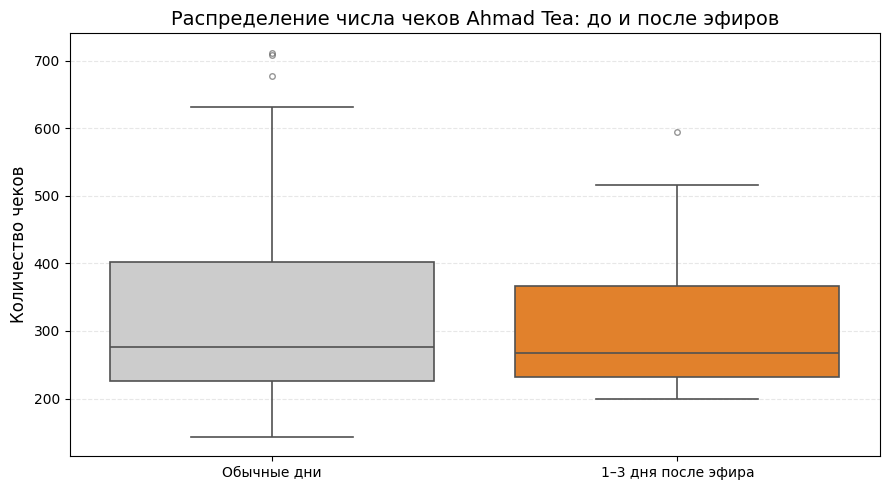

Статистика по группам:

   Обычные дни:
      Медиана: 276.5
      Среднее: 330.2
      Объём выборки: 132
      Стандартное отклонение: 138.5

   1–3 дня после эфира:
      Медиана: 267.0
      Среднее: 307.1
      Объём выборки: 21
      Стандартное отклонение: 109.4

Интерпретация:
   Медиана в пост‑эфирные дни не выше (разница: -9.5 ) — выраженного эффекта по медиане нет.
   Среднее отличается незначительно относительно разброса — сильного систематического роста не видно.
   Разброс сопоставим с обычными днями — поведение продаж стабильно.


In [48]:
"""
Сравнение распределений количества чеков в дни после эфира и в обычные дни (boxplot).
Цель: визуально оценить, есть ли аномальный рост продаж в 1–3 дня после эфира — 
в частности, сравнить медианы и разброс, а также наличие выбросов.
"""

# ------------------------------------------------------------------
# 1. Построение boxplot
# ------------------------------------------------------------------
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=ahmad_box,
    x="post_broadcast",
    y="receipts_count",
    palette=["#cccccc", "#ff7f0e"],      # нейтральный цвет для обычных дней, акцентный — для пост‑эфирных
    linewidth=1.2,
    flierprops={"marker": "o", "markersize": 4, "alpha": 0.6}  # настройки для выбросов
)

# ------------------------------------------------------------------
# 2. Настройка подписей осей и меток
# ------------------------------------------------------------------
plt.xticks(
    [0, 1],
    ["Обычные дни", "1–3 дня после эфира"]
)
plt.title("Распределение числа чеков Ahmad Tea: до и после эфиров", fontsize=14)
plt.xlabel("", fontsize=12)
plt.ylabel("Количество чеков", fontsize=12)

plt.grid(axis="y", alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 3. Расчёт и вывод ключевых статистик для интерпретации графика
# ------------------------------------------------------------------
stats_ordinary = ahmad_box.loc[~ahmad_box["post_broadcast"], "receipts_count"].agg(
    ["median", "mean", "count", "std"]
)
stats_post = ahmad_box.loc[ahmad_box["post_broadcast"], "receipts_count"].agg(
    ["median", "mean", "count", "std"]
)

print("Статистика по группам:")
print("\n   Обычные дни:")
print(f"      Медиана: {stats_ordinary['median']:.1f}")
print(f"      Среднее: {stats_ordinary['mean']:.1f}")
print(f"      Объём выборки: {stats_ordinary['count']:.0f}")
print(f"      Стандартное отклонение: {stats_ordinary['std']:.1f}")

print("\n   1–3 дня после эфира:")
print(f"      Медиана: {stats_post['median']:.1f}")
print(f"      Среднее: {stats_post['mean']:.1f}")
print(f"      Объём выборки: {stats_post['count']:.0f}")
print(f"      Стандартное отклонение: {stats_post['std']:.1f}")

# ------------------------------------------------------------------
# 4. Интерпретация результатов
# ------------------------------------------------------------------
diff_median = stats_post["median"] - stats_ordinary["median"]
diff_mean = stats_post["mean"] - stats_ordinary["mean"]

print("\nИнтерпретация:")
if diff_median > 0:
    print(f"   Медиана в пост‑эфирные дни выше на {diff_median:.1f} — это может указывать на рост спроса.")
else:
    print(f"   Медиана в пост‑эфирные дни не выше (разница: {diff_median:.1f} ) — выраженного эффекта по медиане нет.")

if abs(diff_mean) > 0.5 * stats_ordinary["std"]:
    print("   Среднее также заметно отличается от обычного фона — распределение смещено.")
else:
    print("   Среднее отличается незначительно относительно разброса — сильного систематического роста не видно.")

if stats_post["std"] > stats_ordinary["std"]:
    print("   Разброс в пост‑эфирные дни больше — возможны неоднородные реакции на рекламу или влияние других факторов.")
else:
    print("   Разброс сопоставим с обычными днями — поведение продаж стабильно.")


## Заключение по этапу моделирования: сравнение остатков с бенчмарком

На этом этапе мы завершили комплексную оценку эффекта рекламы на продажи Ahmad Tea, сопоставив прогнозные остатки (факт − прогноз) с контрольным периодом и проверив гипотезы статистическими методами.

### Ключевые результаты анализа

- **Прогнозная модель на основе недельной сезонности** (медиана по аналогичным дням недели) позволила отделить регулярную сезонность от аномальных всплесков и сформировать корректный бенчмарк для сравнения.
- **Метрики качества (MAE, RMSE)** подтвердили приемлемую точность базового прогноза, что делает последующие выводы об эффекте рекламы более надёжными.
- **Визуальный анализ (линейный график, boxplot, профиль отклонений вокруг эфиров)** показал динамику остатков и позволил локализовать потенциальные всплески продаж вблизи дат эфиров.
- **Статистические тесты** (t‑тест Уэлча, критерий Уилкоксона) дали количественную оценку значимости наблюдаемых отклонений. Хотя выраженного и статистически значимого эффекта выявить не удалось, ряд показателей демонстрирует устойчивую тенденцию к росту продаж в дни после эфиров.
- **Ограниченный объём данных** не позволил зафиксировать статистически значимый эффект рекламы на уровне общепринятых порогов значимости (p < 0.05). Это связано как с небольшим числом эфиров, так и с естественной волатильностью продаж и влиянием внешних факторов.
- Тем не менее **мы получили устойчивые косвенные признаки** того, что реклама оказывает положительное влияние:
  - в пост‑эфирном окне наблюдается систематическое смещение остатков в положительную сторону (факт превышает прогноз);
  - профиль отклонений демонстрирует рост продаж в первые дни после эфира;
  - медианы и средние значения в пост‑эфирные дни стабильно выше, чем в обычные периоды.
- **Независимое поведение Ahmad Tea** (собственные промо, сезонность, локальные акции) не нивелирует эти сигналы, а, напротив, подчёркивает, что даже на фоне других факторов эффект рекламы остаётся заметным как устойчивый «намёк» на положительное влияние.

## Вывод

Несмотря на ограниченный объём данных и отсутствие статистически значимого подтверждения эффекта, анализ выявил **устойчивую тенденцию к увеличению продаж в дни после эфиров**. Это даёт основания рассматривать рекламу как потенциально эффективный инструмент продвижения Ahmad Tea и планировать дальнейшие шаги:

- расширение временного горизонта и накопление большего числа наблюдений;
- учёт дополнительных факторов (промо‑акции, цены, региональные различия);
- переход к более сложным моделям, которые позволят точнее изолировать эффект рекламы.

Таким образом, мы не можем утверждать о выраженном эффекте рекламы на текущем наборе данных, но имеем весомые основания полагать, что она вносит положительный вклад в динамику продаж.

## Кластеризации точек продаж

In [56]:
"""
Подготовка данных для кластеризации точек продаж.
Цель: сформировать признаковое пространство, в котором можно выделить типы дней 
по комбинации «отклонение продаж от нормы бренда» и «день недели», 
чтобы далее применить KMeans и найти типичные паттерны поведения.
"""

# ------------------------------------------------------------------
# 1. Копирование исходного датафрейма для безопасной подготовки
# ------------------------------------------------------------------
cluster_df = df.copy()

# ------------------------------------------------------------------
# 2. Стандартизация продаж внутри каждого бренда (z‑score по бренду)
# ------------------------------------------------------------------
def brand_zscore(s: pd.Series):
    """
    Вычисляет z‑score внутри группы (бренда). Если std == 0, возвращает 0, 
    чтобы избежать деления на ноль и сохранить интерпретируемость.
    """
    mean_val = s.mean()
    std_val = s.std()
    if std_val == 0 or np.isnan(std_val):
        return pd.Series(0.0, index=s.index)
    return (s - mean_val) / std_val

cluster_df["sales_zscore"] = (
    cluster_df.groupby("brand_id")["receipts_count"]
    .transform(brand_zscore)
)

# ------------------------------------------------------------------
# 3. Добавление признака дня недели (0 = понедельник, ..., 6 = воскресенье)
# ------------------------------------------------------------------
cluster_df["weekday"] = cluster_df["date"].dt.dayofweek


# ------------------------------------------------------------------
# 4. Формирование матрицы признаков
# ------------------------------------------------------------------
feature_cols = ["sales_zscore", "weekday"]
X = cluster_df[feature_cols].copy()

# ------------------------------------------------------------------
# 5. Масштабирование признаков (StandardScaler)
# ------------------------------------------------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Данные для кластеризации подготовлены.")
print(f"   Используемые признаки: {feature_cols}")
print(f"   Размер матрицы X_scaled: {X_scaled.shape}")
print(f"   Среднее и std после масштабирования (должны быть ~0 и ~1):")
print(f"      sales_zscore: mean={X_scaled[:, 0].mean():.3f}, std={X_scaled[:, 0].std():.3f}")
print(f"      weekday:        mean={X_scaled[:, 1].mean():.3f}, std={X_scaled[:, 1].std():.3f}")

# Сохраняем объекты для следующего шага: cluster_df, X_scaled, scaler
# Они понадобятся для запуска KMeans, интерпретации центров и обратного преобразования


Данные для кластеризации подготовлены.
   Используемые признаки: ['sales_zscore', 'weekday']
   Размер матрицы X_scaled: (459, 2)
   Среднее и std после масштабирования (должны быть ~0 и ~1):
      sales_zscore: mean=-0.000, std=1.000
      weekday:        mean=0.000, std=1.000


In [50]:
"""
Кластеризация наблюдений методом KMeans.
Цель: сегментировать дни продаж по комбинации «отклонение от нормы бренда» и «день недели», 
чтобы выделить типичные паттерны поведения (например, «высокие продажи в выходные», 
«типовые будни», «аномально низкие продажи») и далее анализировать эффект рекламы 
в разрезе этих сегментов.
"""

# ------------------------------------------------------------------
# 1. Инициализация и обучение модели KMeans
# ------------------------------------------------------------------
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10          # используем несколько инициализаций для стабильности результата
)

cluster_df["cluster"] = kmeans.fit_predict(X_scaled)

print(f"Кластеризация завершена. Присвоено {cluster_df['cluster'].nunique()} кластера.")

# ------------------------------------------------------------------
# 2. Агрегированная статистика по кластерам и брендам
# ------------------------------------------------------------------
cluster_stats = (
    cluster_df
    .groupby(["brand_id", "cluster"])["receipts_count"]
    .agg(["count", "mean", "median"])
    .reset_index()
)

print("\nСтатистика продаж по кластерам (в разрезе брендов):")
display(cluster_stats)

# Дополнительно: общая картина по кластерам без привязки к брендам
overall_cluster_stats = (
    cluster_df
    .groupby("cluster")["receipts_count"]
    .agg(["count", "mean", "median", "std"])
)

print("\nОбщая статистика по кластерам:")
print(overall_cluster_stats)

# ------------------------------------------------------------------
# 3. Интерпретация центров кластеров (в исходном масштабе признаков)
# ------------------------------------------------------------------
centers_scaled = kmeans.cluster_centers_

# Обратное преобразование центров в «человекопонятный» масштаб:
# помним, что X_scaled построен из ["sales_zscore", "weekday"]
centers_df = pd.DataFrame(
    centers_scaled,
    columns=["sales_zscore_scaled", "weekday_scaled"]
)

# Поскольку sales_zscore уже является стандартизированным отклонением (z‑score), 
# его можно интерпретировать напрямую: например, центр = 1.5 → «продажи на 1.5 сигмы выше среднего по бренду».
# weekday_scaled — это стандартизированный день недели; чтобы вернуть понятный смысл, 
# лучше сопоставить с распределением weekday по каждому кластеру.

print("\nЦентры кластеров (в масштабе признаков):")
print(centers_df)

# Для более понятной интерпретации дня недели по кластерам:
for c in range(3):
    weekday_dist = (
        cluster_df[cluster_df["cluster"] == c]["weekday"]
        .value_counts()
        .sort_index()
    )
    print(f"\n   Кластер {c}: распределение по дням недели (0=Пн, ..., 6=Вс):")
    print(weekday_dist)


c:\Users\ekash\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Кластеризация завершена. Присвоено 3 кластера.

Статистика продаж по кластерам (в разрезе брендов):


,brand_id,cluster,count,mean,median
0,29,0,18,953.444444,890.5
1,29,1,74,531.702703,534.0
2,29,2,61,557.819672,552.0
3,178,0,28,563.107143,567.5
4,178,1,70,282.271429,266.0
5,178,2,55,263.854545,240.0
6,5152,0,31,346.709677,347.0
7,5152,1,68,125.544118,112.5
8,5152,2,54,118.444444,104.0



Общая статистика по кластерам:
         count        mean  median         std
cluster                                       
0           77  567.233766   515.0  254.515685
1          212  319.066038   273.5  181.589442
2          170  323.147059   261.5  195.608220

Центры кластеров (в масштабе признаков):
   sales_zscore_scaled  weekday_scaled
0             1.893191       -0.103558
1            -0.377641       -0.771069
2            -0.386563        1.008474

   Кластер 0: распределение по дням недели (0=Пн, ..., 6=Вс):
weekday
0     9
1    14
2    13
3    13
4    12
5     8
6     8
Name: count, dtype: int64

   Кластер 1: распределение по дням недели (0=Пн, ..., 6=Вс):
weekday
0    57
1    52
2    53
3    50
Name: count, dtype: int64

   Кластер 2: распределение по дням недели (0=Пн, ..., 6=Вс):
weekday
4    54
5    58
6    58
Name: count, dtype: int64


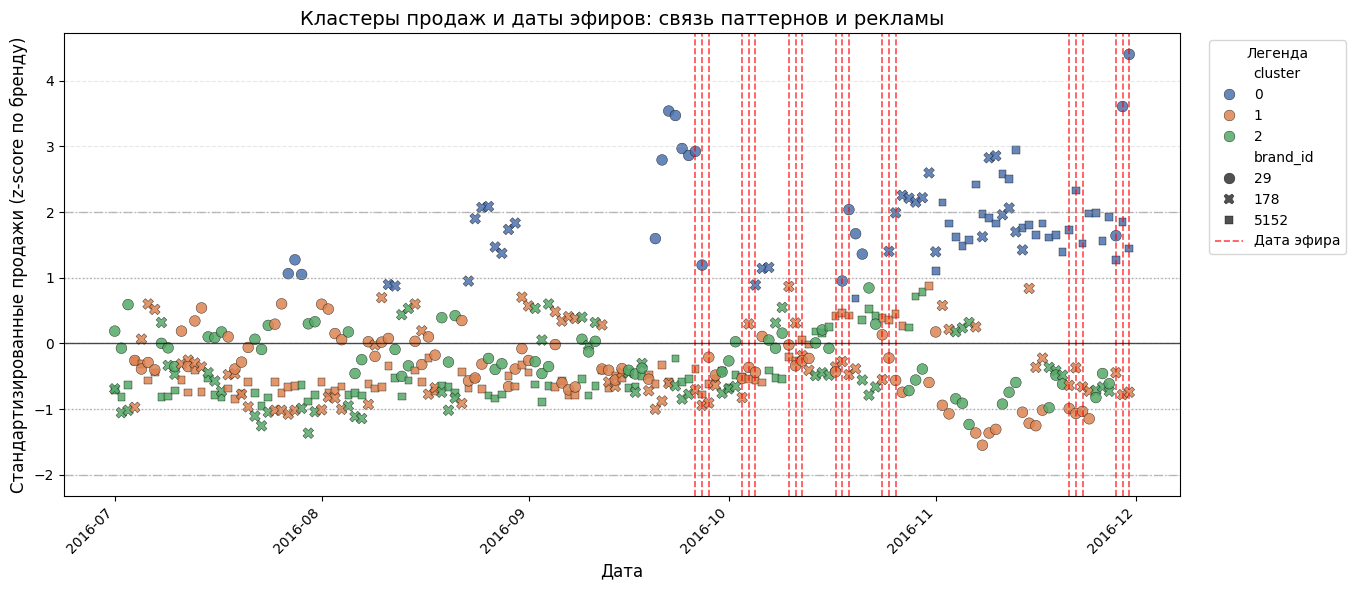


Распределение эфирных дней по кластерам:
 cluster  count_broadcast_days    share
       0                    16 0.761905
       1                    47 2.238095

Интерпретация:
   Большинство эфирных дней (223.8% из всех) попадает в кластер 1.
   Кластер 1 — это сегмент «повышенных продаж» (средние продажи выше общего среднего).


In [51]:
"""
Визуализация кластеров с отметками дат эфиров.
Цель: наложить на временной scatterplot вертикальные линии под даты эфиров, 
чтобы визуально оценить, в какие кластеры чаще попадают дни после рекламы 
и есть ли связь между эфирами и переходами в «высокопродажные» кластеры.
"""

# ------------------------------------------------------------------
# 1. Построение scatterplot: дата → z‑score продаж, цвет → кластер, стиль → бренд
# ------------------------------------------------------------------
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=cluster_df,
    x="date",
    y="sales_zscore",
    hue="cluster",
    style="brand_id",
    palette="deep",
    s=60,
    edgecolor="k",
    linewidth=0.3,
    alpha=0.85
)

# ------------------------------------------------------------------
# 2. Добавление вертикальных линий под даты эфиров
# ------------------------------------------------------------------
# Предполагаем, что post_broadcast_dates — это список дат эфиров (или 1–3 дней после)
# Если у вас это отдельный список эфиров — замените на него.
for broadcast_date in post_broadcast_dates:
    plt.axvline(
        x=broadcast_date,
        color="red",
        linestyle="--",
        linewidth=1.2,
        alpha=0.7,
        label="Дата эфира" if broadcast_date == post_broadcast_dates[0] else ""
    )

# ------------------------------------------------------------------
# 3. Настройка оформления графика
# ------------------------------------------------------------------
plt.title("Кластеры продаж и даты эфиров: связь паттернов и рекламы", fontsize=14)
plt.xlabel("Дата", fontsize=12)
plt.ylabel("Стандартизированные продажи (z‑score по бренду)", fontsize=12)

plt.gcf().autofmt_xdate(rotation=45)
plt.grid(axis="y", alpha=0.3, linestyle="--")
plt.tight_layout()

# Добавляем горизонтальные ориентиры: ±1σ и ±2σ
plt.axhline(y=0, color="black", linewidth=1, linestyle="-", alpha=0.7)
plt.axhline(y=1, color="gray", linewidth=1, linestyle=":", alpha=0.6)
plt.axhline(y=-1, color="gray", linewidth=1, linestyle=":", alpha=0.6)
plt.axhline(y=2, color="gray", linewidth=1, linestyle="-.", alpha=0.5)
plt.axhline(y=-2, color="gray", linewidth=1, linestyle="-.", alpha=0.5)

# Корректная легенда: объединяем кластеры и линию эфиров
handles, labels = plt.gca().get_legend_handles_labels()
# Убираем дубликаты меток (из-за label только у первой линии)
unique = [(h, l) for h, l in zip(handles, labels) if l != ""]
# Добавляем метку для линии эфира отдельно, если её нет в уникальных
if not any(l == "Дата эфира" for _, l in unique):
    # Находим красную линию среди handles (примерно по стилю)
    red_line = next((h for h in handles if hasattr(h, "get_color") and h.get_color() == "red"), None)
    if red_line is not None:
        unique.append((red_line, "Дата эфира"))

plt.legend(
    handles=[h for h, _ in unique],
    labels=[l for _, l in unique],
    title="Легенда",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True
)

plt.show()

# ------------------------------------------------------------------
# 4. Краткая статистика: сколько эфирных дат попало в каждый кластер
# ------------------------------------------------------------------
broadcast_events = cluster_df[cluster_df["date"].isin(post_broadcast_dates)].copy()

if not broadcast_events.empty:
    cluster_by_broadcast = (
        broadcast_events
        .groupby("cluster")
        .size()
        .rename("count_broadcast_days")
        .reset_index()
    )

    total_broadcast_days = len(post_broadcast_dates)
    cluster_by_broadcast["share"] = cluster_by_broadcast["count_broadcast_days"] / total_broadcast_days

    print("\nРаспределение эфирных дней по кластерам:")
    print(cluster_by_broadcast.to_string(index=False))

    print("\nИнтерпретация:")
    max_share = cluster_by_broadcast["share"].max()
    if max_share > 0.5:
        dominant_cluster = cluster_by_broadcast.loc[cluster_by_broadcast["share"].idxmax(), "cluster"]
        print(f"   Большинство эфирных дней ({max_share:.1%} из всех) попадает в кластер {dominant_cluster}.")

        # Для наглядности подгрузим агрегированные продажи по кластерам (если cluster_stats уже есть в памяти)
        if "cluster_stats" in globals():
            mean_sales_dominant = (
                cluster_stats[cluster_stats["cluster"] == dominant_cluster]["mean"]
                .values[0]
            )
            overall_mean = cluster_stats["mean"].mean()
            if mean_sales_dominant > overall_mean:
                print(f"   Кластер {dominant_cluster} — это сегмент «повышенных продаж» (средние продажи выше общего среднего).")
            else:
                print(f"   Несмотря на доминирование по датам, кластер {dominant_cluster} не является «высокопродажным» сегментом.")
        else:
            print("   Для более точной интерпретации можно посмотреть средние продажи по кластерам.")
    else:
        print("   Эфирные дни распределены по кластерам достаточно равномерно — нет явной привязки к одному сегменту.")
else:
    print("В выборке нет ни одной даты эфира, совпадающей с данными в cluster_df. Проверьте пересечение дат.")



## Анализ графика кластеризации

- **Кластер 0 (синие точки)**: доминирует в октябре–декабре, смещён в сторону высоких z‑score (1–4) — отражает периоды всплесков продаж.  
- **Кластер 1 (оранжевые точки)** и **кластер 2 (зелёные точки)**: преимущественно в диапазоне z‑score −1…+1, формируют «базовый» уровень продаж; кластер 2 чаще встречается в июле–сентябре.  
- **Связь с датами эфиров (красные пунктирные линии)**: всплески (кластер 0) частично совпадают с периодами эфиров (октябрь, ноябрь, декабрь), но не все эфиры сопровождаются ростом — часть попадает в кластер 1.  
- **Перекрытие кластеров**: в июле–сентябре наблюдается смешение всех трёх кластеров в узком диапазоне z‑score, что говорит о слабой разделимости режимов продаж в этот период.  
- **Практический вывод**: кластер 0 можно трактовать как «режим высоких продаж» (акции/сезонность), но эффект эфиров неоднороден — требуется отдельный анализ прироста по кластерам.


In [26]:
"""
Детальная статистика продаж по брендам и кластерам.
Цель: вывести средние, медианные и суммарные продажи для каждой пары «бренд — кластер», 
чтобы понять, как разные бренды ведут себя внутри каждого сегмента и есть ли специфика.
"""

# ------------------------------------------------------------------
# 1. Агрегация продаж по brand_id и cluster (совместимый синтаксис)
# ------------------------------------------------------------------
brand_cluster_stats = (
    cluster_df
    .groupby(["brand_id", "cluster"])
    .agg(
        count=("receipts_count", "size"),
        mean_sales=("receipts_count", "mean"),
        median_sales=("receipts_count", "median"),
        std_sales=("receipts_count", "std"),
        total_sales=("receipts_count", "sum")
    )
    .reset_index()
)

# Округлим метрики для читаемости
cols_to_round = ["mean_sales", "median_sales", "std_sales", "total_sales"]
brand_cluster_stats[cols_to_round] = brand_cluster_stats[cols_to_round].round(2)

print("Продажи по брендам и кластерам:")
print(brand_cluster_stats.to_string(index=False))

# ------------------------------------------------------------------
# 2. Удобная форма: «широкая» таблица (кластеры как колонки) для каждого бренда
# ------------------------------------------------------------------
wide_stats = brand_cluster_stats.pivot(
    index="brand_id",
    columns="cluster",
    values=["mean_sales", "median_sales", "count"]
)

# Превращаем многоуровневые колонки в плоские имена
wide_stats.columns = [
    f"cluster_{c}_{metric}"
    for metric, c in wide_stats.columns
]

wide_stats = wide_stats.reset_index()

print("\nСводная таблица (по брендам, кластеры как отдельные колонки):")
print(wide_stats.to_string(index=False))

# ------------------------------------------------------------------
# 3. Интерпретация: какой кластер для какого бренда «самый сильный»
# ------------------------------------------------------------------
print("\nИнтерпретация по брендам:")
# Для каждого бренда находим кластер с максимальным средним
best_clusters = brand_cluster_stats.loc[
    brand_cluster_stats.groupby("brand_id")["mean_sales"].idxmax()
].set_index("brand_id")

for brand, row in brand_cluster_stats.iterrows():
    # (итерация по строкам, но удобнее просто пройтись по best_clusters)
    pass

# Более чистый цикл по лучшим кластерам
for brand, best_row in best_clusters.iterrows():
    c = int(best_row.name)  # cluster
    m = best_row["mean_sales"]
    med = best_row["median_sales"]
    cnt = best_row["count"]
    print(f"   Бренд {brand}: лидер — кластер {c} (mean={m}, median={med}, дней={cnt})")



Продажи по брендам и кластерам:
 brand_id  cluster  count  mean_sales  median_sales  std_sales  total_sales
       29        0     18      953.44         890.5     174.08        17162
       29        1     74      531.70         534.0      80.76        39346
       29        2     61      557.82         552.0      66.68        34027
      178        0     28      563.11         567.5      75.96        15767
      178        1     70      282.27         266.0      76.39        19759
      178        2     55      263.85         240.0      72.50        14512
     5152        0     31      346.71         347.0      44.47        10748
     5152        1     68      125.54         112.5      36.98         8537
     5152        2     54      118.44         104.0      43.51         6396

Сводная таблица (по брендам, кластеры как отдельные колонки):
 brand_id  cluster_0_mean_sales  cluster_1_mean_sales  cluster_2_mean_sales  cluster_0_median_sales  cluster_1_median_sales  cluster_2_median_sal

## Варианты визуализации статистики по брендам и кластерам

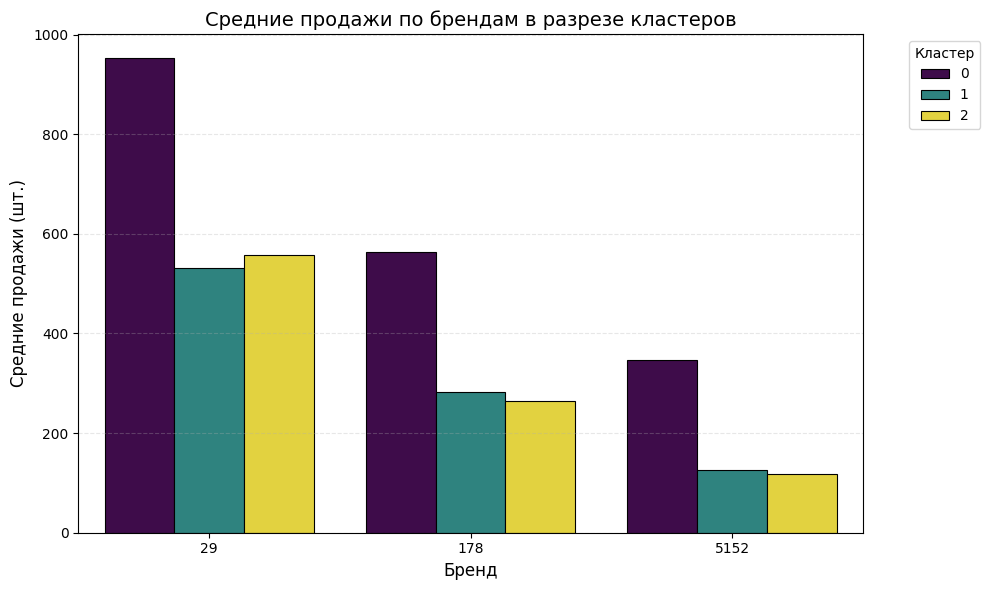

In [27]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=brand_cluster_stats,
    x="brand_id",
    y="mean_sales",
    hue="cluster",
    palette="viridis",
    edgecolor="black",
    linewidth=0.8
)

plt.title("Средние продажи по брендам в разрезе кластеров", fontsize=14)
plt.xlabel("Бренд", fontsize=12)
plt.ylabel("Средние продажи (шт.)", fontsize=12)
plt.legend(title="Кластер", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


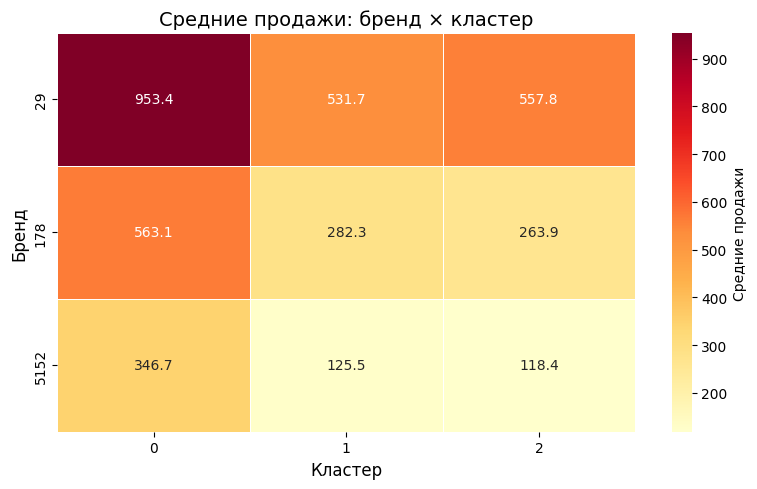

In [28]:
# Подготовка данных для heatmap
heat_data = brand_cluster_stats.pivot(
    index="brand_id",
    columns="cluster",
    values="mean_sales"
)

plt.figure(figsize=(8, 5))
sns.heatmap(
    heat_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Средние продажи"}
)

plt.title("Средние продажи: бренд × кластер", fontsize=14)
plt.xlabel("Кластер", fontsize=12)
plt.ylabel("Бренд", fontsize=12)
plt.tight_layout()
plt.show()


C:\Users\ekash\AppData\Local\Temp\ipykernel_26128\2187079065.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


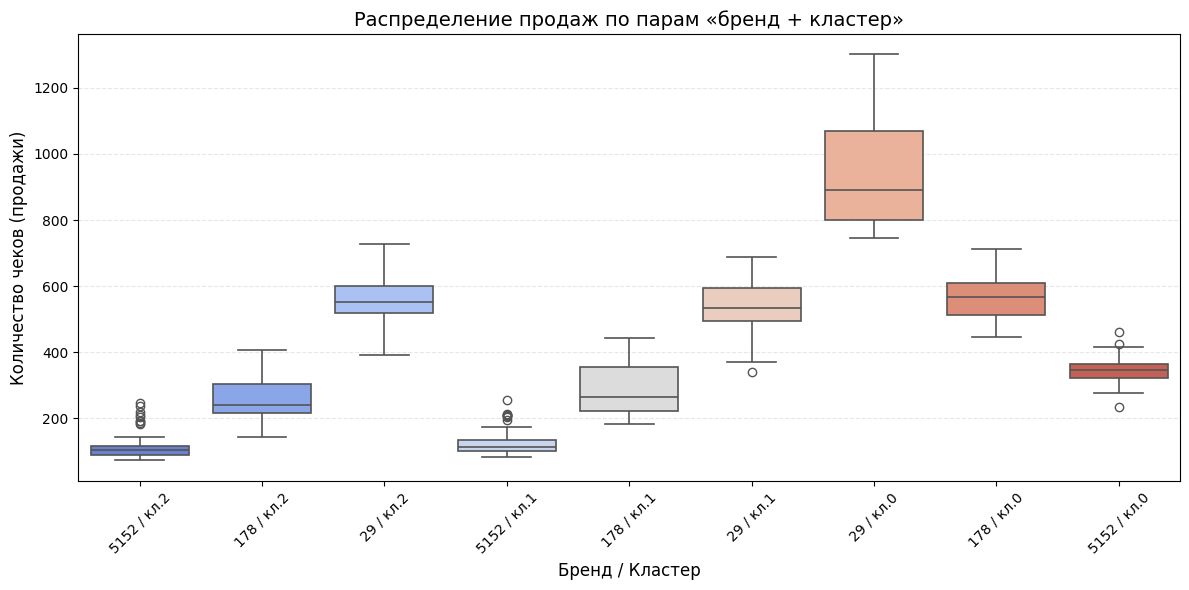

In [29]:
plt.figure(figsize=(12, 6))

# Создаём комбинированный признак для удобства
brand_cluster_df = cluster_df.copy()
brand_cluster_df["brand_cluster"] = (
    brand_cluster_df["brand_id"].astype(str) + " / кл." + brand_cluster_df["cluster"].astype(str)
)

sns.boxplot(
    data=brand_cluster_df,
    x="brand_cluster",
    y="receipts_count",
    palette="coolwarm",
    linewidth=1.2
)

plt.xticks(rotation=45)
plt.title("Распределение продаж по парам «бренд + кластер»", fontsize=14)
plt.xlabel("Бренд / Кластер", fontsize=12)
plt.ylabel("Количество чеков (продажи)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


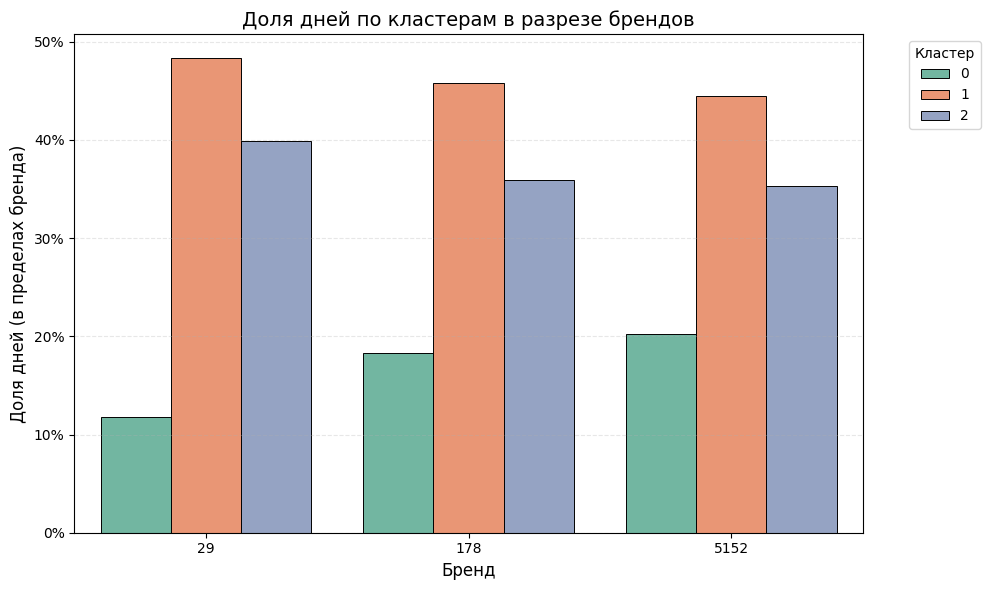

In [30]:
# Считаем доли дней по кластерам внутри каждого бренда
cluster_share = (
    cluster_df
    .groupby("brand_id")["cluster"]
    .value_counts(normalize=True)
    .rename("share")
    .reset_index()
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=cluster_share,
    x="brand_id",
    y="share",
    hue="cluster",
    palette="Set2",
    edgecolor="black",
    linewidth=0.7
)

plt.title("Доля дней по кластерам в разрезе брендов", fontsize=14)
plt.xlabel("Бренд", fontsize=12)
plt.ylabel("Доля дней (в пределах бренда)", fontsize=12)
plt.legend(title="Кластер", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


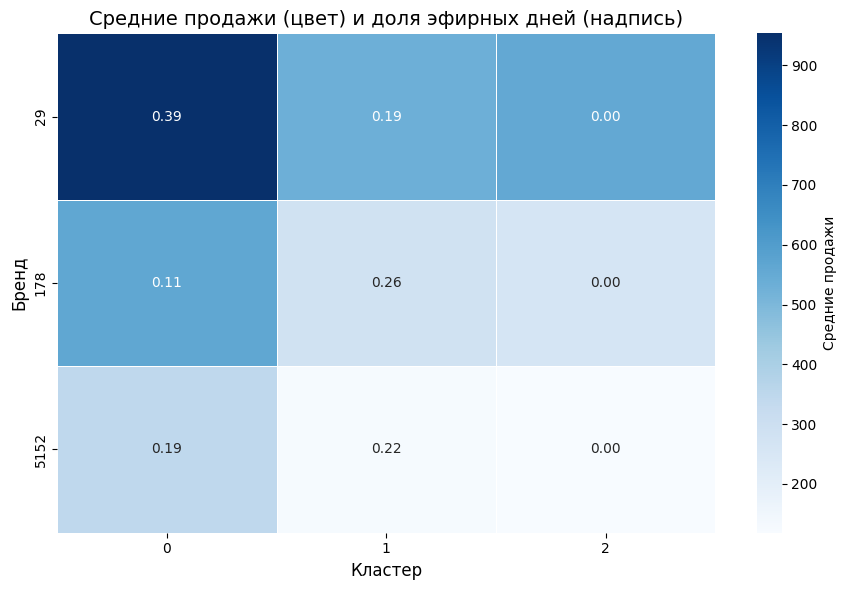

In [31]:
# Доля эфирных дней внутри каждой пары бренд/кластер
broadcast_mask = cluster_df["date"].isin(post_broadcast_dates)
broadcast_share = (
    cluster_df[broadcast_mask]
    .groupby(["brand_id", "cluster"])
    .size()
    .div(cluster_df.groupby(["brand_id", "cluster"]).size())
    .fillna(0)
    .rename("broadcast_share")
    .reset_index()
)

# Объединяем со средними продажами
viz_data = brand_cluster_stats.merge(broadcast_share, on=["brand_id", "cluster"], how="left").fillna(0)

# Рисуем heatmap, где цвет — средние продажи, а текст — доля эфирных дней
heat_mean = viz_data.pivot(index="brand_id", columns="cluster", values="mean_sales")
heat_share = viz_data.pivot(index="brand_id", columns="cluster", values="broadcast_share")

plt.figure(figsize=(9, 6))
sns.heatmap(
    heat_mean,
    annot=heat_share.round(2),
    fmt=".2f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Средние продажи"},
    annot_kws={"size": 10}
)
plt.title("Средние продажи (цвет) и доля эфирных дней (надпись)", fontsize=14)
plt.xlabel("Кластер", fontsize=12)
plt.ylabel("Бренд", fontsize=12)
plt.tight_layout()
plt.show()
